### 01.01 Scope and reading guide

**Document Unwarping – Dataset EDA (20 November 2026).** This notebook examines the four validated datasets **before** model development. It uses the inventories exported by Dataset Download and Setup: UVDoc Final (20,000 images / 4,032 geometry variants), UVDoc Benchmark (50), DocUNet (130), and DIR300 (300). The current inventory is the authority at runtime; listed counts are expectations from the provided audit, not hardcoded substitutes.

**Navigation:** Each Markdown and code cell has its own `SS.CC` label (`05.03`, for example). Run top to bottom. A stage writes a corresponding section of `documentation/dataset_eda_summary.md` as soon as it finishes. Every saved figure has a **textual companion** in that Markdown report, plus a CSV data table. Visual galleries have sample-ID/path inspection tables and a manual-review template; image content itself cannot be completely conveyed by a numeric table.

**Scope:** data integrity, source dependence, image statistics, classical cues, raw 2D/3D geometry, synthetic/real differences, reference compatibility, and a geometry-grouped validation proposal. No training, model inference, model-performance metrics, or unwarping algorithms.

**Source conventions:** [Official UVDoc loader](https://github.com/tanguymagne/UVDoc/blob/main/data_UVDoc.py), [UVDoc data utility](https://github.com/tanguymagne/UVDoc/blob/main/data_utils.py), and [UVDoc dataset release](https://github.com/tanguymagne/UVDoc-Dataset). Raw `grid2d` values are image-pixel positions in the official pre-crop loader; after its randomized tight crop the 2D grid is normalized to `[-1, 1]`. This notebook measures **raw** annotations and does not claim to reproduce a randomized training transform.

In [1]:
# 01.02 | Imports and environment
import os
import json
import math
import re
import shutil
import hashlib
import platform
import sys
import zipfile
from pathlib import Path, PurePosixPath
from datetime import datetime, timezone

import cv2
import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
from tqdm.auto import tqdm
from IPython.display import display, Markdown

print('Python:', sys.version.split()[0], '| Platform:', platform.platform())
print('NumPy:', np.__version__, '| pandas:', pd.__version__, '| OpenCV:', cv2.__version__)
print('Pillow:', Image.__version__, '| h5py:', h5py.__version__)
print('GPU is not required for dataset EDA.')


Python: 3.13.18 | Platform: Linux-6.6.159+-x86_64-with-glibc2.39
NumPy: 2.4.6 | pandas: 2.2.3 | OpenCV: 5.0.0
Pillow: 11.3.0 | h5py: 3.14.0
GPU is not required for dataset EDA.


In [2]:
# 01.03 | Mount Drive and set analysis parameters
try :
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError :
    print('Not running in Colab; using DOCUMENT_UNWARPING_ROOT if specified.')

PROJECT_ROOT = Path(os.environ.get('DOCUMENT_UNWARPING_ROOT', '/content/drive/MyDrive/Document Unwarping'))
META_ROOT    = PROJECT_ROOT / 'dataset/_metadata'
FIG_ROOT     = PROJECT_ROOT / 'runs/dataset_eda/figures'
REVIEW_ROOT  = PROJECT_ROOT / 'runs/dataset_eda/galleries'
REPORT_PATH  = PROJECT_ROOT / 'documentation/dataset_eda_summary.md'
LOCAL_FINAL  = Path('/content/uvdoc_runtime/UVDoc_final')
DRIVE_FINAL  = PROJECT_ROOT / 'dataset/UVDoc/UVDoc_final'
BENCH_ROOT   = PROJECT_ROOT / 'dataset/UVDoc/UVDoc_benchmark'

SEED                 = 20261120
MAX_RGB_FINAL        = 2400   # Reproducible sample; edit to 20000 for full pixel-level pass.
MAX_CLASSICAL_FINAL  = 240    # Classical diagnostic features on synthetic images.
MAX_MASK_GEOMETRIES  = 32     # Auxiliary mask/UV samples, not a full auxiliary annotation audit.
IMAGE_MAX_EDGE       = 512    # Longest side for photometric and edge descriptors.
VALIDATION_FRACTION  = 0.10  # Fraction of independent base-geometry groups.
REUSE_CACHED_RESULTS = True
STAGE_FINAL_IF_MISSING = True  # Copy/extract existing ZIP to Colab local disk; never redownload.

for folder in (META_ROOT, FIG_ROOT, REVIEW_ROOT, REPORT_PATH.parent) :
    folder.mkdir(parents=True, exist_ok=True)
if (not PROJECT_ROOT.is_dir()) :
    raise FileNotFoundError(f'Project root not accessible: {PROJECT_ROOT}')
print('Project root:', PROJECT_ROOT)
print('Report:', REPORT_PATH)
print('UVDoc Final local cache exists:', (LOCAL_FINAL / 'img').is_dir())


Mounted at /content/drive
Project root: /content/drive/MyDrive/Document Unwarping
Report: /content/drive/MyDrive/Document Unwarping/documentation/dataset_eda_summary.md
UVDoc Final local cache exists: False


In [3]:
# 01.04 | Stage UVDoc Final locally if the runtime restarted
source_archive = PROJECT_ROOT / 'dataset/UVDoc/_archives/UVDoc_final.zip'


def staged_uvdoc_complete(path : Path) :
    expected_files = {'img' : ('*.png', 20000), 'grid2d' : ('*.mat', 4032),
                      'grid3d' : ('*.mat', 4032), 'metadata_sample' : ('*.json', 20000)}
    return all((path / folder).is_dir() and sum(1 for _ in (path / folder).glob(pattern)) == count
               for folder, (pattern, count) in expected_files.items())


if (not staged_uvdoc_complete(LOCAL_FINAL) and STAGE_FINAL_IF_MISSING) :
    if (not source_archive.is_file()) :
        raise FileNotFoundError(f'Missing local UVDoc Final and persistent archive: {source_archive}')

    local_archive = Path('/content/UVDoc_final.zip')
    extract_root  = LOCAL_FINAL.parent
    with zipfile.ZipFile(source_archive) as zf :
        members = [i for i in zf.infolist() if i.filename.startswith('UVDoc_final/') and not i.is_dir()
                   and not PurePosixPath(i.filename).name.startswith('._')]
        target_bytes = sum(i.file_size for i in members)
        archive_bytes = source_archive.stat().st_size
        existing_archive_bytes = local_archive.stat().st_size if local_archive.is_file() else 0
        needed = target_bytes + (0 if existing_archive_bytes == archive_bytes else archive_bytes) + 3 * 1024 ** 3
        free_bytes = shutil.disk_usage('/content').free
        print(f'Local free: {free_bytes / 2 ** 30:.2f} GiB; conservative space request: {needed / 2 ** 30:.2f} GiB')
        if (free_bytes < needed) :
            raise RuntimeError('Insufficient local Colab storage to stage UVDoc Final. Do not extract to mounted Drive.')

    if (existing_archive_bytes != archive_bytes) :
        partial = local_archive.with_suffix('.zip.partial')
        with source_archive.open('rb') as src, partial.open('wb') as dst :
            with tqdm(total=archive_bytes, unit='B', unit_scale=True, desc='Copy UVDoc ZIP locally') as bar :
                for block in iter(lambda : src.read(16 * 1024 ** 2), b'') :
                    dst.write(block)
                    bar.update(len(block))
        partial.replace(local_archive)

    with zipfile.ZipFile(local_archive) as zf :
        with tqdm(total=sum(i.file_size for i in members), unit='B', unit_scale=True, desc='Extract UVDoc locally') as bar :
            for info in members :
                parts = PurePosixPath(info.filename).parts
                if (not parts or parts[0] != 'UVDoc_final' or '..' in parts or '\\' in info.filename) :
                    raise ValueError(f'Unsafe ZIP member path: {info.filename}')
                target = extract_root.joinpath(*parts)
                if (target.is_file() and target.stat().st_size == info.file_size) :
                    bar.update(info.file_size)
                    continue
                target.parent.mkdir(parents=True, exist_ok=True)
                partial = target.with_name(target.name + '.partial')
                with zf.open(info) as src, partial.open('wb') as dst :
                    for block in iter(lambda : src.read(8 * 1024 ** 2), b'') :
                        dst.write(block)
                        bar.update(len(block))
                partial.replace(target)

FINAL_ROOT = LOCAL_FINAL if staged_uvdoc_complete(LOCAL_FINAL) else DRIVE_FINAL
if (not (FINAL_ROOT / 'img').is_dir()) :
    raise FileNotFoundError(f'UVDoc Final unavailable at both {LOCAL_FINAL} and {DRIVE_FINAL}')
print('UVDoc Final active path:', FINAL_ROOT)


Local free: 225.70 GiB; conservative space request: 59.24 GiB


Copy UVDoc ZIP locally:   0%|          | 0.00/29.5G [00:00<?, ?B/s]

Extract UVDoc locally:   0%|          | 0.00/30.9G [00:00<?, ?B/s]

UVDoc Final active path: /content/uvdoc_runtime/UVDoc_final


In [4]:
# 01.05 | Report and figure helpers
REPORT_STATE_PATH = META_ROOT / 'eda_report_sections.json'
manifest_digests = {p.name : hashlib.sha256(p.read_bytes()).hexdigest() for p in META_ROOT.glob('*_manifest.csv')}
report_config = {'seed' : SEED, 'max_rgb_final' : MAX_RGB_FINAL, 'max_classical_final' : MAX_CLASSICAL_FINAL,
                 'max_mask_geometries' : MAX_MASK_GEOMETRIES, 'image_max_edge' : IMAGE_MAX_EDGE,
                 'validation_fraction' : VALIDATION_FRACTION, 'manifests' : manifest_digests}
report_signature = hashlib.sha256(json.dumps(report_config, sort_keys=True).encode()).hexdigest()
prior_state = json.loads(REPORT_STATE_PATH.read_text(encoding='utf-8')) if REPORT_STATE_PATH.is_file() else {}
REPORT_BLOCKS = prior_state.get('sections', {}) if prior_state.get('signature') == report_signature else {}


def markdown_table(frame : pd.DataFrame, limit : int = 25) :
    if (frame is None or frame.empty) :
        return '_No rows available._'
    table = frame.head(limit).copy().fillna('')
    headers = [str(x).replace('|', '/') for x in table.columns]
    rows = ['| ' + ' | '.join(headers) + ' |', '| ' + ' | '.join(['---'] * len(headers)) + ' |']
    for record in table.itertuples(index=False, name=None) :
        values = [str(round(v, 5) if isinstance(v, (float, np.floating)) and np.isfinite(v) else v).replace('|', '/')
                  .replace('\n', ' ') for v in record]
        rows.append('| ' + ' | '.join(values) + ' |')
    if (len(frame) > limit) :
        rows.append(f'\n_Showing {limit:,} of {len(frame):,} rows; full CSV is saved separately._')
    return '\n'.join(rows)


def save_report() :
    heading = ['# Document Unwarping – Dataset EDA Report', '',
               f'Updated (UTC): {datetime.now(timezone.utc).isoformat()}', '',
               'This document contains measured dataset statistics, figure companion tables, and explicit limitations. '
               'It is generated incrementally by `[20.11] Dataset_EDA.ipynb` and does not claim model-performance results.', '',
               f'- Image statistics: {IMAGE_MAX_EDGE}px longest side for pixel-based descriptors.',
               f'- UVDoc Final pixel sample limit: {MAX_RGB_FINAL:,} (metadata inventory covers all records).',
               f'- Random seed: {SEED}.',
               '- All method-feasibility descriptors are **proxies**, not validated detectors.', '',
               '## Completed analyses', '']
    for section, content in sorted(REPORT_BLOCKS.items()) :
        heading.extend([f'### {section}', content, ''])
    REPORT_PATH.write_text('\n'.join(heading), encoding='utf-8')
    REPORT_STATE_PATH.write_text(json.dumps({'signature' : report_signature, 'sections' : REPORT_BLOCKS},
                                            ensure_ascii=False, indent=2), encoding='utf-8')


def publish(number : str, title : str, notes : str, tables : dict | None = None) :
    content = [notes]
    for label, frame in (tables or {}).items() :
        filename = f'{number.replace(".", "_")}_{re.sub(r"[^a-z0-9]+", "_", label.lower()).strip("_")}.csv'
        full_path = META_ROOT / filename
        frame.to_csv(full_path, index=False)
        content.extend(['', f'**{label}** · full data: `dataset/_metadata/{filename}`', '', markdown_table(frame)])
    REPORT_BLOCKS[f'{number} {title}'] = '\n'.join(content)
    save_report()
    print(f'Report updated: {REPORT_PATH} | {number} {title}')


def figure_with_data(number : str, title : str, fig, frame : pd.DataFrame, notes : str) :
    image_name = f'{number.replace(".", "_")}.png'
    fig.savefig(FIG_ROOT / image_name, dpi=140, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    publish(number, title, notes + f'\n\nFigure: `runs/dataset_eda/figures/{image_name}`. '
            'The table below is the numeric/text companion for this figure.', {'Figure data' : frame})


def resolve_path(relative_path : str) :
    value = str(relative_path).replace('\\', '/')
    prefix = 'dataset/UVDoc/UVDoc_final/'
    if (value.startswith(prefix)) :
        return FINAL_ROOT / value[len(prefix) :]
    if (value.startswith('dataset/')) :
        return PROJECT_ROOT / value
    raise ValueError(f'Unexpected manifest path: {relative_path}')


def sample_ids(frame : pd.DataFrame, n : int, seed : int = SEED) :
    if (len(frame) <= n) :
        return frame.copy()
    return frame.sample(n=n, random_state=seed).sort_index().copy()


In [5]:
# 01.06 | Read Notebook 1 inventories and verify data roots
manifest_files = {
    'UVDoc Final'     : 'uvdoc_final_manifest.csv',
    'UVDoc Benchmark' : 'uvdoc_benchmark_manifest.csv',
    'DocUNet'         : 'docunet_manifest.csv',
    'DIR300'          : 'dir300_manifest.csv',
}
manifests = {}
for name, filename in manifest_files.items() :
    path = META_ROOT / filename
    if (not path.is_file()) :
        raise FileNotFoundError(f'Run Notebook 1 to create {path}')
    manifests[name] = pd.read_csv(path, dtype=str, keep_default_na=False)

integrity = json.loads((META_ROOT / 'integrity_report.json').read_text(encoding='utf-8'))
acquisition = json.loads((META_ROOT / 'acquisition.json').read_text(encoding='utf-8'))
source_keys = {'UVDoc Final' : 'uvdoc_final', 'UVDoc Benchmark' : 'uvdoc_benchmark', 'DocUNet' : 'docunet', 'DIR300' : 'dir300'}
expected = {'UVDoc Final' : 20000, 'UVDoc Benchmark' : 50, 'DocUNet' : 130, 'DIR300' : 300}
readiness = []
for name, frame in manifests.items() :
    key = source_keys[name]
    ready = bool(integrity.get(key, {}).get('ready', False))
    if (not ready or len(frame) != expected[name]) :
        raise RuntimeError(f'{name}: audit ready={ready}, manifest rows={len(frame)} (expected {expected[name]}); rerun Notebook 1')
    if (frame.sample_id.duplicated().any()) :
        raise ValueError(f'{name} has duplicate sample IDs')
    path_col = 'image_path' if name.startswith('UVDoc') else 'input_path'
    sample = sample_ids(frame, min(len(frame), 12))
    missing = [r for r in sample[path_col] if not resolve_path(r).is_file()]
    if (missing) :
        raise FileNotFoundError(f'{name}: paths do not resolve: {missing[:3]}')
    readiness.append({'dataset' : name, 'rows' : len(frame), 'expected' : expected[name],
                      'audit_ready' : ready, 'sample_paths_checked' : len(sample), 'missing_sample_paths' : len(missing)})
readiness_table = pd.DataFrame(readiness)
display(readiness_table)
publish('01.06', 'Inventory readiness', 'All listed datasets must pass Notebook 1 structural checks. '
        'Small path probes verify the current runtime; full decoding occurs in later stages.', {'Readiness' : readiness_table})


,dataset,rows,expected,audit_ready,sample_paths_checked,missing_sample_paths
0,UVDoc Final,20000,20000,True,12,0
1,UVDoc Benchmark,50,50,True,12,0
2,DocUNet,130,130,True,12,0
3,DIR300,300,300,True,12,0


Report updated: /content/drive/MyDrive/Document Unwarping/documentation/dataset_eda_summary.md | 01.06 Inventory readiness


### 02.01 Source dependence and dataset composition

Treat rendered UVDoc images as **dependent observations**. `geom_name` identifies a geometric variant, while filenames such as `00_00000_1_0_0` suggest four sibling variants (`_0_0`, `_0_1`, `_1_0`, `_1_1`). We will check that pattern empirically and retain all variants of one base capture together in validation. The split is **proposed**, not automatically declared final by a random image split.

In [6]:
# 02.02 | Count geometry, source textures, and backgrounds
uvfinal = manifests['UVDoc Final'].copy()
uvbench = manifests['UVDoc Benchmark'].copy()
for frame in (uvfinal, uvbench) :
    frame['base_geometry'] = frame.geom_name.map(lambda x : x.rsplit('_', 2)[0] if len(x.split('_')) >= 5 else x)
    frame['variant'] = frame.geom_name.map(lambda x : '_'.join(x.rsplit('_', 2)[-2 :]) if len(x.split('_')) >= 5 else 'unknown')

composition = []
for name, frame in [('UVDoc Final', uvfinal), ('UVDoc Benchmark', uvbench)] :
    composition.append({'dataset' : name, 'images' : len(frame), 'geometry_variants' : frame.geom_name.nunique(),
                        'base_geometries' : frame.base_geometry.nunique(),
                        'textures' : frame.texture_name.nunique(), 'backgrounds' : frame.background_name.nunique(),
                        'invalid_annotations' : int((frame.annotation_status != 'valid').sum())})
composition_table = pd.DataFrame(composition)
variant_count = uvfinal.groupby('base_geometry').geom_name.nunique().value_counts().rename_axis('variants_per_base').reset_index(name='base_geometry_count')
render_counts = uvfinal.groupby('base_geometry').size().rename('renders').reset_index()
print('Source variants:', variant_count.to_string(index=False))
display(composition_table)
publish('02.02', 'Source composition', 'Base-geometry grouping removes the final two underscore-separated suffixes. '
        'It is supported here by the observed four-variant pattern; do not equate variants with physically independent captures.',
        {'Dataset composition' : composition_table, 'Geometry variant multiplicity' : variant_count,
         'Renderings per base geometry' : render_counts.describe().reset_index().rename(columns={'index':'statistic'})})


Source variants:  variants_per_base  base_geometry_count
                 4                 1008


,dataset,images,geometry_variants,base_geometries,textures,backgrounds,invalid_annotations
0,UVDoc Final,20000,4032,1008,3003,5470,0
1,UVDoc Benchmark,50,50,50,50,50,0


Report updated: /content/drive/MyDrive/Document Unwarping/documentation/dataset_eda_summary.md | 02.02 Source composition


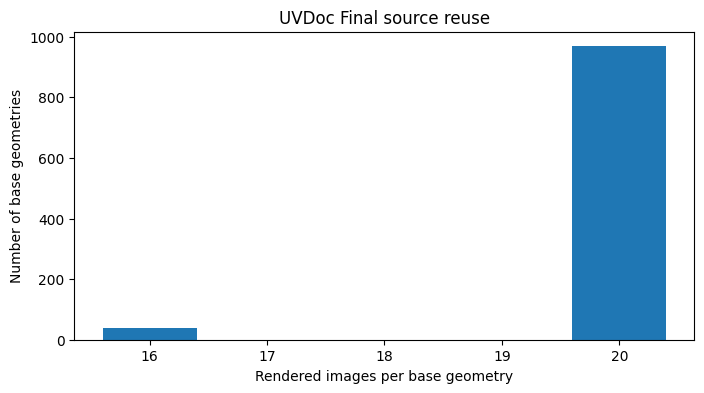

Report updated: /content/drive/MyDrive/Document Unwarping/documentation/dataset_eda_summary.md | 02.03 Renderings per base geometry


In [7]:
# 02.03 | Visualize geometry reuse with a numeric companion
reuse_hist = render_counts.renders.value_counts().sort_index().rename_axis('renderings_per_base').reset_index(name='base_count')
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(reuse_hist.renderings_per_base, reuse_hist.base_count)
ax.set(xlabel='Rendered images per base geometry', ylabel='Number of base geometries', title='UVDoc Final source reuse')
figure_with_data('02.03', 'Renderings per base geometry', fig, reuse_hist,
                 'Each bar counts independently named base geometries with that many rendered images.')


In [8]:
# 02.04 | Check source identity overlap between training and benchmark
overlap_rows = []
for field in ('sample_id', 'geom_name', 'base_geometry', 'texture_name', 'background_name') :
    a = set(uvfinal[field].dropna()) - {''}
    b = set(uvbench[field].dropna()) - {''}
    same = sorted(a & b)
    overlap_rows.append({'identity' : field, 'final_unique' : len(a), 'benchmark_unique' : len(b),
                         'shared_identifiers' : len(same), 'examples' : ', '.join(same[:12])})
overlap_table = pd.DataFrame(overlap_rows)
display(overlap_table)
publish('02.04', 'Cross-release source overlap',
        'Identical `sample_id` values are local to each release and are **not** evidence of a duplicate image. '
        'Shared texture filenames indicate a possible repeated content source, not proof of identical pixels. '
        'A geometry-disjoint benchmark does not guarantee texture-disjoint content.', {'Overlap counts' : overlap_table})


,identity,final_unique,benchmark_unique,shared_identifiers,examples
0,sample_id,20000,50,50,"00000, 00001, 00002, 00003, 00004, 00005, 0000..."
1,geom_name,4032,50,0,
2,base_geometry,1008,50,0,
3,texture_name,3003,50,12,"04-01.png, 04-02.png, 04-05.png, 04-06.png, 04..."
4,background_name,5470,50,0,


Report updated: /content/drive/MyDrive/Document Unwarping/documentation/dataset_eda_summary.md | 02.04 Cross-release source overlap


### 03.01 Image representation and photometric statistics

Inventory **all** image headers (dimensions, modes, orientation, and file size) without loading every image into memory. For photometric descriptors, fully evaluate the 130 DocUNet inputs, 300 DIR300 inputs, 50 UVDoc Benchmark inputs, and a seeded UVDoc Final subsample (configurable above). Originals and reference scans remain separate image types. Edge and blur numbers are only *diagnostic proxies*.

In [9]:
# 03.02 | Collect image-header metadata across datasets
image_sources = []
for name, frame in manifests.items() :
    if (name.startswith('UVDoc')) :
        image_sources.extend((name, 'rendered', r.sample_id, r.image_path) for r in frame.itertuples(index=False))
    elif (name == 'DocUNet') :
        image_sources.extend((name, 'crop', r.sample_id, r.input_path) for r in frame.itertuples(index=False))
        image_sources.extend((name, 'original', r.sample_id, r.original_path) for r in frame.itertuples(index=False))
        images = frame[['document_id', 'reference_path']].drop_duplicates()
        image_sources.extend((name, 'scan', r.document_id, r.reference_path) for r in images.itertuples(index=False))
    else :
        image_sources.extend((name, 'dist', r.sample_id, r.input_path) for r in frame.itertuples(index=False))
        image_sources.extend((name, 'gt', r.sample_id, r.reference_path) for r in frame.itertuples(index=False))

meta_cache = META_ROOT / 'eda_image_metadata.csv'
if (REUSE_CACHED_RESULTS and meta_cache.is_file()) :
    image_meta = pd.read_csv(meta_cache, dtype={'sample_id':str}, keep_default_na=False)
    if (len(image_meta) != len(image_sources)) :
        print('Cache row count differs from current sources; rebuilding.')
        image_meta = pd.DataFrame()
else :
    image_meta = pd.DataFrame()

if (image_meta.empty) :
    records = []
    for name, role, sample_id, relative_path in tqdm(image_sources, desc='Inspect image headers') :
        path = resolve_path(relative_path)
        row  = {'dataset' : name, 'image_role' : role, 'sample_id' : str(sample_id),
                'path' : relative_path, 'file_bytes' : path.stat().st_size if path.exists() else np.nan}
        try :
            with Image.open(path) as image :
                row.update({'width' : image.width, 'height' : image.height, 'mode' : image.mode,
                            'format' : image.format, 'exif_orientation' : int(image.getexif().get(274, 1)),
                            'error' : ''})
        except (OSError, ValueError) as exc :
            row['error'] = f'{type(exc).__name__}: {exc}'
        records.append(row)
    image_meta = pd.DataFrame(records)
    image_meta.to_csv(meta_cache, index=False)

image_meta['width'] = pd.to_numeric(image_meta['width'], errors='coerce')
image_meta['height'] = pd.to_numeric(image_meta['height'], errors='coerce')
image_meta['megapixels'] = image_meta.width * image_meta.height / 1e6
image_meta['aspect_ratio'] = image_meta.width / image_meta.height
print(f'Image headers: {len(image_meta):,}; failed: {int((image_meta.error != "").sum()):,}')


Inspect image headers:   0%|          | 0/20975 [00:00<?, ?it/s]

Image headers: 20,975; failed: 0


In [10]:
# 03.03 | Summarize resolutions, modes, orientation, and outliers
valid_meta = image_meta.loc[image_meta.error == ''].copy()
size_summary = valid_meta.groupby(['dataset', 'image_role']).agg(
    count=('path', 'size'), width_min=('width', 'min'), width_median=('width', 'median'),
    width_p95=('width', lambda x : x.quantile(0.95)), height_median=('height', 'median'),
    mp_median=('megapixels', 'median'), mp_p95=('megapixels', lambda x : x.quantile(0.95)),
    aspect_median=('aspect_ratio', 'median')).reset_index()
mode_summary = valid_meta.groupby(['dataset', 'image_role', 'mode', 'exif_orientation']).size().reset_index(name='count')
failed_images = image_meta.loc[image_meta.error != '', ['dataset', 'sample_id', 'path', 'error']]
display(size_summary)
display(mode_summary)
publish('03.03', 'Image representation',
        'All images are checked at header level. EXIF orientation is recorded, not used to overwrite originals. '
        'Aspect ratio and pixel count are not measures of geometric distortion.',
        {'Resolution summary' : size_summary, 'Modes and EXIF' : mode_summary, 'Failed image headers' : failed_images})


,dataset,image_role,count,width_min,width_median,width_p95,height_median,mp_median,mp_p95,aspect_median
0,DIR300,dist,300,2041,3024.0,3472.00,4032.0,12.192768,16.054528,0.750000
1,DIR300,gt,300,1336,1634.0,2028.00,2352.0,3.835176,5.793185,0.702955
2,DocUNet,crop,130,654,1339.0,1789.85,1718.0,2.265320,3.800575,0.783018
3,DocUNet,original,130,3024,3024.0,4032.00,4032.0,12.192768,12.192768,0.750000
4,DocUNet,scan,65,677,2398.0,2550.00,3190.0,7.478572,8.415000,0.750801
5,UVDoc Benchmark,rendered,50,785,908.0,1025.95,1217.0,1.131349,1.313140,0.743016
6,UVDoc Final,rendered,20000,488,488.0,488.00,712.0,0.347456,0.347456,0.685393


,dataset,image_role,mode,exif_orientation,count
0,DIR300,dist,RGB,1,298
1,DIR300,dist,RGBA,1,2
2,DIR300,gt,RGB,1,299
3,DIR300,gt,RGBA,1,1
4,DocUNet,crop,RGB,1,130
5,DocUNet,original,RGB,1,100
6,DocUNet,original,RGB,6,30
7,DocUNet,scan,RGB,1,38
8,DocUNet,scan,RGBA,1,27
9,UVDoc Benchmark,rendered,RGB,1,50


Report updated: /content/drive/MyDrive/Document Unwarping/documentation/dataset_eda_summary.md | 03.03 Image representation


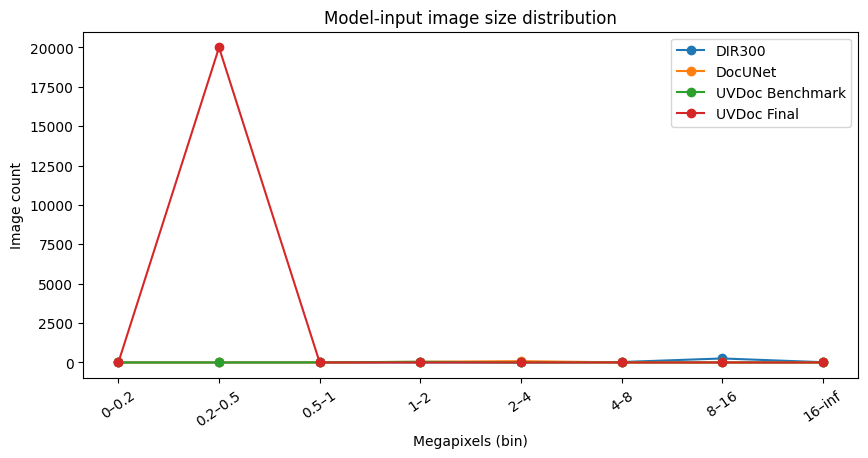

Report updated: /content/drive/MyDrive/Document Unwarping/documentation/dataset_eda_summary.md | 03.04 Image size distribution


In [11]:
# 03.04 | Plot image-size distributions and export histogram bins
role_meta = valid_meta.loc[((valid_meta.dataset == 'UVDoc Final') & (valid_meta.image_role == 'rendered')) |
                           ((valid_meta.dataset == 'UVDoc Benchmark') & (valid_meta.image_role == 'rendered')) |
                           ((valid_meta.dataset == 'DocUNet') & (valid_meta.image_role == 'crop')) |
                           ((valid_meta.dataset == 'DIR300') & (valid_meta.image_role == 'dist'))]
bins = np.array([0, 0.2, 0.5, 1, 2, 4, 8, 16, np.inf])
size_hist = []
for name, group in role_meta.groupby('dataset') :
    counts, edges = np.histogram(group.megapixels.dropna(), bins=bins)
    for i, count in enumerate(counts) :
        size_hist.append({'dataset' : name, 'mp_bin' : f'{edges[i]:g}–{edges[i+1]:g}', 'count' : int(count)})
size_hist = pd.DataFrame(size_hist)
fig, ax = plt.subplots(figsize=(10, 4.5))
for name, group in size_hist.groupby('dataset') :
    ax.plot(group.mp_bin, group['count'], marker='o', label=name)
ax.set(xlabel='Megapixels (bin)', ylabel='Image count', title='Model-input image size distribution')
ax.tick_params(axis='x', rotation=35)
ax.legend()
figure_with_data('03.04', 'Image size distribution', fig, size_hist,
                 'Absolute counts reflect different dataset sizes; compare proportions with the full CSV before drawing conclusions.')


In [12]:
# 03.05 | Compute reproducible photometric descriptors
def load_rgb(path : Path, max_edge : int = IMAGE_MAX_EDGE) :
    with Image.open(path) as image :
        image = ImageOps.exif_transpose(image)
        if (image.mode in ('RGBA', 'LA') or 'transparency' in image.info) :
            rgba = image.convert('RGBA')
            background = Image.new('RGBA', rgba.size, (255, 255, 255, 255))
            image = Image.alpha_composite(background, rgba).convert('RGB')
        else :
            image = image.convert('RGB')
        if (max(image.size) > max_edge) :
            image.thumbnail((max_edge, max_edge), Image.Resampling.BILINEAR)
        return np.asarray(image)


def photometric_descriptor(rgb : np.ndarray) :
    gray  = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    hsv   = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    edges = cv2.Canny(gray, 75, 175)
    h, w  = gray.shape
    tiles = [float(tile.mean()) for tile in np.array_split(gray, 4, axis=0) for tile in np.array_split(tile, 4, axis=1)]
    return {'luminance_mean' : float(gray.mean()), 'luminance_std' : float(gray.std()),
            'saturation_mean' : float(hsv[:, :, 1].mean()), 'laplacian_variance' : float(cv2.Laplacian(gray, cv2.CV_64F).var()),
            'edge_fraction' : float((edges > 0).mean()), 'tile_luminance_range' : max(tiles) - min(tiles),
            'dark_fraction' : float((gray < 50).mean()), 'bright_fraction' : float((gray > 230).mean())}

pixel_candidates = role_meta.copy()
final_pixel = pixel_candidates.loc[pixel_candidates.dataset == 'UVDoc Final']
other_pixel = pixel_candidates.loc[pixel_candidates.dataset != 'UVDoc Final']
pixel_candidates = pd.concat([sample_ids(final_pixel, MAX_RGB_FINAL), other_pixel], ignore_index=True)
photometric_cache = META_ROOT / f'eda_photometric_{MAX_RGB_FINAL}_{IMAGE_MAX_EDGE}.csv'
if (REUSE_CACHED_RESULTS and photometric_cache.is_file()) :
    pixels = pd.read_csv(photometric_cache, dtype={'sample_id':str}, keep_default_na=False)
    if (len(pixels) != len(pixel_candidates)) :
        pixels = pd.DataFrame()
else :
    pixels = pd.DataFrame()

if (pixels.empty) :
    records = []
    for r in tqdm(pixel_candidates.itertuples(index=False), total=len(pixel_candidates), desc='Pixel descriptors') :
        row = {'dataset' : r.dataset, 'sample_id' : r.sample_id, 'path' : r.path}
        try :
            row.update(photometric_descriptor(load_rgb(resolve_path(r.path))))
            row['error'] = ''
        except (OSError, ValueError, cv2.error) as exc :
            row['error'] = f'{type(exc).__name__}: {exc}'
        records.append(row)
    pixels = pd.DataFrame(records)
    pixels.to_csv(photometric_cache, index=False)

pixel_ok = pixels.loc[pixels.error == ''].copy()
pixel_columns = ['luminance_mean', 'luminance_std', 'saturation_mean', 'laplacian_variance',
                 'edge_fraction', 'tile_luminance_range', 'dark_fraction', 'bright_fraction']
ph_summary = pixel_ok.groupby('dataset')[pixel_columns].agg(['count', 'median', 'mean', 'std']).round(4)
ph_summary.columns = ['_'.join(c) for c in ph_summary.columns]
ph_summary = ph_summary.reset_index()
display(ph_summary)
publish('03.05', 'Photometric descriptors',
        f'Pixel-level quantities are computed on images downscaled to at most {IMAGE_MAX_EDGE}px per side. '
        f'UVDoc Final uses a seeded {len(final_pixel) if len(final_pixel) < MAX_RGB_FINAL else MAX_RGB_FINAL:,}-image sample; '
        'other benchmark inputs are fully processed. Laplacian variance is a scale-dependent sharpness proxy, '
        'tile luminance range an illumination proxy, and edge fraction not a document-boundary detector.',
        {'Photometric dataset summary' : ph_summary, 'Pixel decoding errors' : pixels.loc[pixels.error != '']})


Pixel descriptors:   0%|          | 0/2880 [00:00<?, ?it/s]

,dataset,luminance_mean_count,luminance_mean_median,luminance_mean_mean,luminance_mean_std,luminance_std_count,luminance_std_median,luminance_std_mean,luminance_std_std,saturation_mean_count,...,tile_luminance_range_mean,tile_luminance_range_std,dark_fraction_count,dark_fraction_median,dark_fraction_mean,dark_fraction_std,bright_fraction_count,bright_fraction_median,bright_fraction_mean,bright_fraction_std
0,DIR300,300,132.7349,132.4644,18.2613,300,56.2185,56.1921,13.3875,300,...,97.9686,29.1632,300,0.0654,0.1191,0.1325,300,0.0000,0.0063,0.0165
1,DocUNet,130,164.9636,161.7357,22.3675,130,54.2676,53.7862,14.3344,130,...,82.4913,31.1332,130,0.0557,0.0858,0.0979,130,0.0016,0.0507,0.1005
2,UVDoc Benchmark,50,146.8137,144.7798,17.8005,50,39.5943,39.1037,8.7260,50,...,74.1430,24.9859,50,0.0102,0.0219,0.0275,50,0.0000,0.0083,0.0195
3,UVDoc Final,2400,125.6757,121.3586,30.8847,2400,43.5728,44.3284,11.9738,2400,...,68.7071,27.0203,2400,0.0657,0.1332,0.1961,2400,0.0000,0.0138,0.0476


Report updated: /content/drive/MyDrive/Document Unwarping/documentation/dataset_eda_summary.md | 03.05 Photometric descriptors


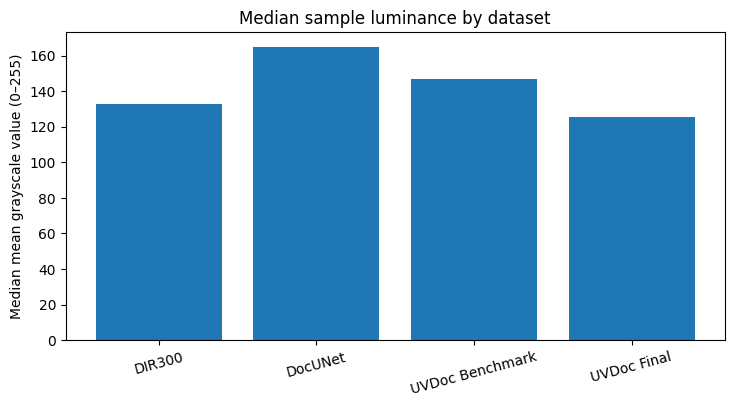

Report updated: /content/drive/MyDrive/Document Unwarping/documentation/dataset_eda_summary.md | 03.06 Cross-dataset appearance summary


In [13]:
# 03.06 | Plot appearance variation and export the plotted numbers
appearance_table = pixel_ok.groupby('dataset').agg(n=('sample_id','size'),
    luminance_median=('luminance_mean','median'), contrast_median=('luminance_std','median'),
    edge_fraction_median=('edge_fraction','median'), tile_range_median=('tile_luminance_range','median')).reset_index()
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.bar(appearance_table.dataset, appearance_table.luminance_median)
ax.set(ylabel='Median mean grayscale value (0–255)', title='Median sample luminance by dataset')
ax.tick_params(axis='x', rotation=15)
figure_with_data('03.06', 'Cross-dataset appearance summary', fig, appearance_table,
                 'The plotted median luminance and additional companion columns describe inputs, not method performance.')


### 04.01 Visual audit and classical cues

These cells provide **diagnostic evidence**, not a finished boundary or text-line detection system. Edge maps, Hough segments, and contour candidates can show where classical methods may have usable inputs. A small editable manual-review CSV records conditions that cannot be inferred reliably from low-level statistics alone.

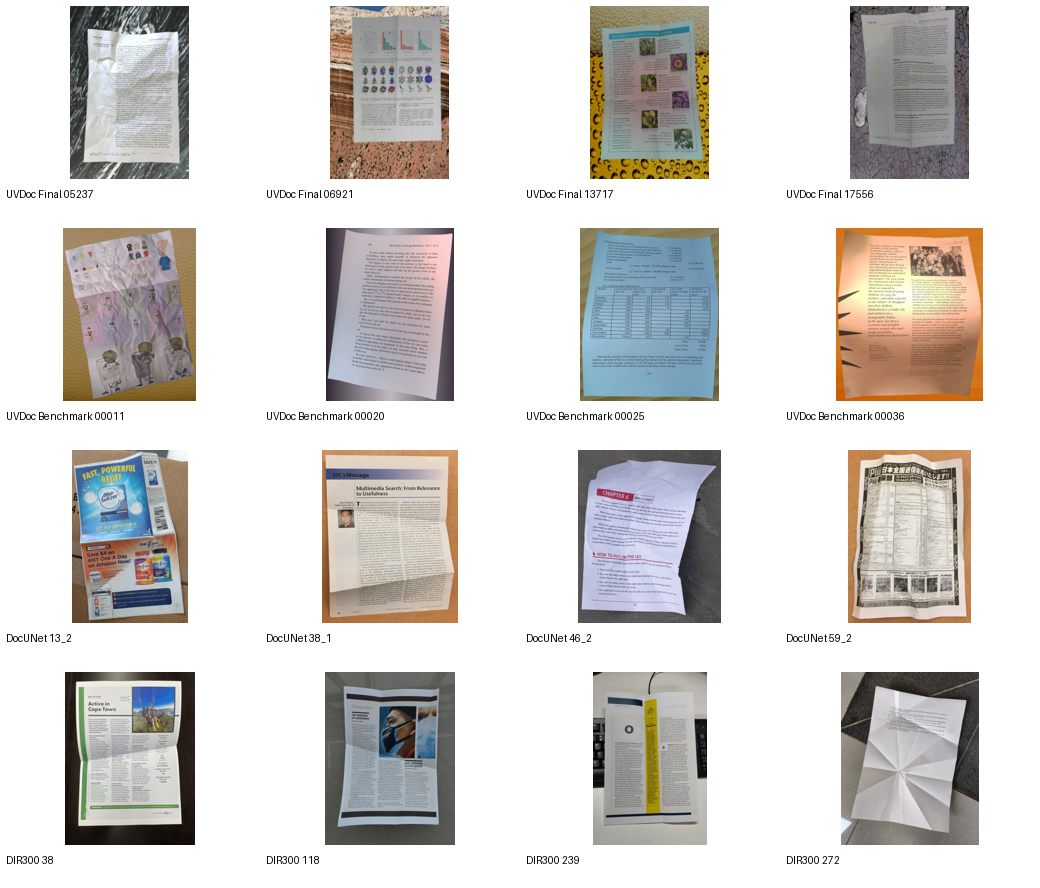

Report updated: /content/drive/MyDrive/Document Unwarping/documentation/dataset_eda_summary.md | 04.02 Representative input gallery


In [14]:
# 04.02 | Create representative input–reference and synthetic galleries
from PIL import ImageDraw


def make_contact_sheet(items : list, title : str, output_path : Path, cell_size=(260, 185), columns=4) :
    width, height = cell_size
    rows = math.ceil(len(items) / columns)
    canvas = Image.new('RGB', (columns * width, rows * (height + 37)), 'white')
    draw = ImageDraw.Draw(canvas)
    for n, (label, path) in enumerate(items) :
        try :
            with Image.open(path) as image :
                image = ImageOps.exif_transpose(image).convert('RGB')
                image.thumbnail((width - 12, height - 12))
                x = (n % columns) * width + (width - image.width) // 2
                y = (n // columns) * (height + 37) + (height - image.height) // 2
                canvas.paste(image, (x, y))
        except OSError :
            pass
        draw.text(((n % columns) * width + 6, (n // columns) * (height + 37) + height + 3), str(label)[:40], fill='black')
    canvas.save(output_path)
    display(canvas.resize((min(canvas.width, 1200), int(canvas.height * min(1200 / canvas.width, 1)))))

selected = []
for name in ('UVDoc Final', 'UVDoc Benchmark', 'DocUNet', 'DIR300') :
    frame = sample_ids(manifests[name], 4, SEED + len(name))
    for row in frame.itertuples(index=False) :
        path = row.image_path if name.startswith('UVDoc') else row.input_path
        selected.append({'dataset' : name, 'sample_id' : row.sample_id, 'input_path' : path,
                         'reference_path' : getattr(row, 'reference_path', '')})
gallery_table = pd.DataFrame(selected)
items = [(f'{r.dataset} {r.sample_id}', resolve_path(r.input_path)) for r in gallery_table.itertuples(index=False)]
gallery_path = REVIEW_ROOT / 'representative_inputs.jpg'
make_contact_sheet(items, 'Representative model inputs', gallery_path)
publish('04.02', 'Representative input gallery',
        'Figure: `runs/dataset_eda/galleries/representative_inputs.jpg`. '
        'The companion table records every pictured sample ID and source path. '
        'Visual content requires manual review; do not infer page curvature from image IDs.',
        {'Gallery identity and paths' : gallery_table})


In [15]:
# 04.03 | Measure edge, line, and contour candidates on real and synthetic samples
def classical_cues(rgb : np.ndarray) :
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    h, w = gray.shape
    edges = cv2.Canny(gray, 70, 160)
    segments = cv2.HoughLinesP(edges, rho=1, theta=np.pi / 180, threshold=max(20, int(min(h,w)*0.09)),
                               minLineLength=max(16, int(w * 0.12)), maxLineGap=max(8, int(w * 0.03)))
    lines = np.empty((0, 4)) if segments is None else segments.reshape(-1, 4)
    long_lines = 0
    horizontal = 0
    for x1, y1, x2, y2 in lines :
        length = math.hypot(int(x2) - int(x1), int(y2) - int(y1))
        angle  = abs(math.degrees(math.atan2(int(y2) - int(y1), int(x2) - int(x1))))
        if (length >= 0.25 * w) :
            long_lines += 1
            horizontal += int(min(angle, 180 - angle) <= 15)
    contours, _ = cv2.findContours(edges, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)
    largest = max(contours, key=cv2.contourArea) if contours else None
    area = float(cv2.contourArea(largest) / (w*h)) if largest is not None else 0.0
    corners = len(cv2.approxPolyDP(largest, 0.03*cv2.arcLength(largest, True), True)) if largest is not None else 0
    return {'edge_fraction' : float((edges > 0).mean()), 'hough_segments' : len(lines),
            'long_segments' : long_lines, 'long_near_horizontal' : horizontal,
            'largest_contour_area_fraction' : area, 'largest_contour_vertices' : corners}

real_diagnostics = pd.concat([manifests['DocUNet'].assign(dataset='DocUNet'),
                              manifests['DIR300'].assign(dataset='DIR300')], ignore_index=True)
final_classic = sample_ids(uvfinal, MAX_CLASSICAL_FINAL, SEED + 43)
probe_rows = []
for name, frame in [('DocUNet', manifests['DocUNet']), ('DIR300', manifests['DIR300']), ('UVDoc Final', final_classic)] :
    for r in tqdm(frame.itertuples(index=False), total=len(frame), desc=f'Classical probes: {name}') :
        relative = r.image_path if name.startswith('UVDoc') else r.input_path
        row = {'dataset' : name, 'sample_id' : r.sample_id, 'input_path' : relative}
        try :
            row.update(classical_cues(load_rgb(resolve_path(relative))))
            row['error'] = ''
        except (OSError, ValueError, cv2.error) as exc :
            row['error'] = f'{type(exc).__name__}: {exc}'
        probe_rows.append(row)
classical_table = pd.DataFrame(probe_rows)
classical_table.to_csv(META_ROOT / 'eda_classical_cues.csv', index=False)
classical_summary = classical_table.loc[classical_table.error == ''].groupby('dataset').agg(
    n=('sample_id', 'size'), median_edges=('edge_fraction', 'median'),
    median_segments=('hough_segments', 'median'), median_long_segments=('long_segments', 'median'),
    median_contour_area=('largest_contour_area_fraction','median')).reset_index()
display(classical_summary)
publish('04.03', 'Classical cue probes',
        'OpenCV Canny/Hough and largest-contour descriptors are unvalidated probes; Hough lines may be paper edges or graphical elements rather than text lines. '
        'A four-vertex contour is **not** verified page-corner detection. No classical unwarping is implemented.',
        {'Probe summary' : classical_summary, 'Probe errors' : classical_table.loc[classical_table.error != '']})


Classical probes: DocUNet:   0%|          | 0/130 [00:00<?, ?it/s]

Classical probes: DIR300:   0%|          | 0/300 [00:00<?, ?it/s]

Classical probes: UVDoc Final:   0%|          | 0/240 [00:00<?, ?it/s]

,dataset,n,median_edges,median_segments,median_long_segments,median_contour_area
0,DIR300,300,0.101601,253.0,100.0,0.515906
1,DocUNet,130,0.133294,357.0,121.5,0.068188
2,UVDoc Final,240,0.127593,298.0,86.0,0.008864


Report updated: /content/drive/MyDrive/Document Unwarping/documentation/dataset_eda_summary.md | 04.03 Classical cue probes


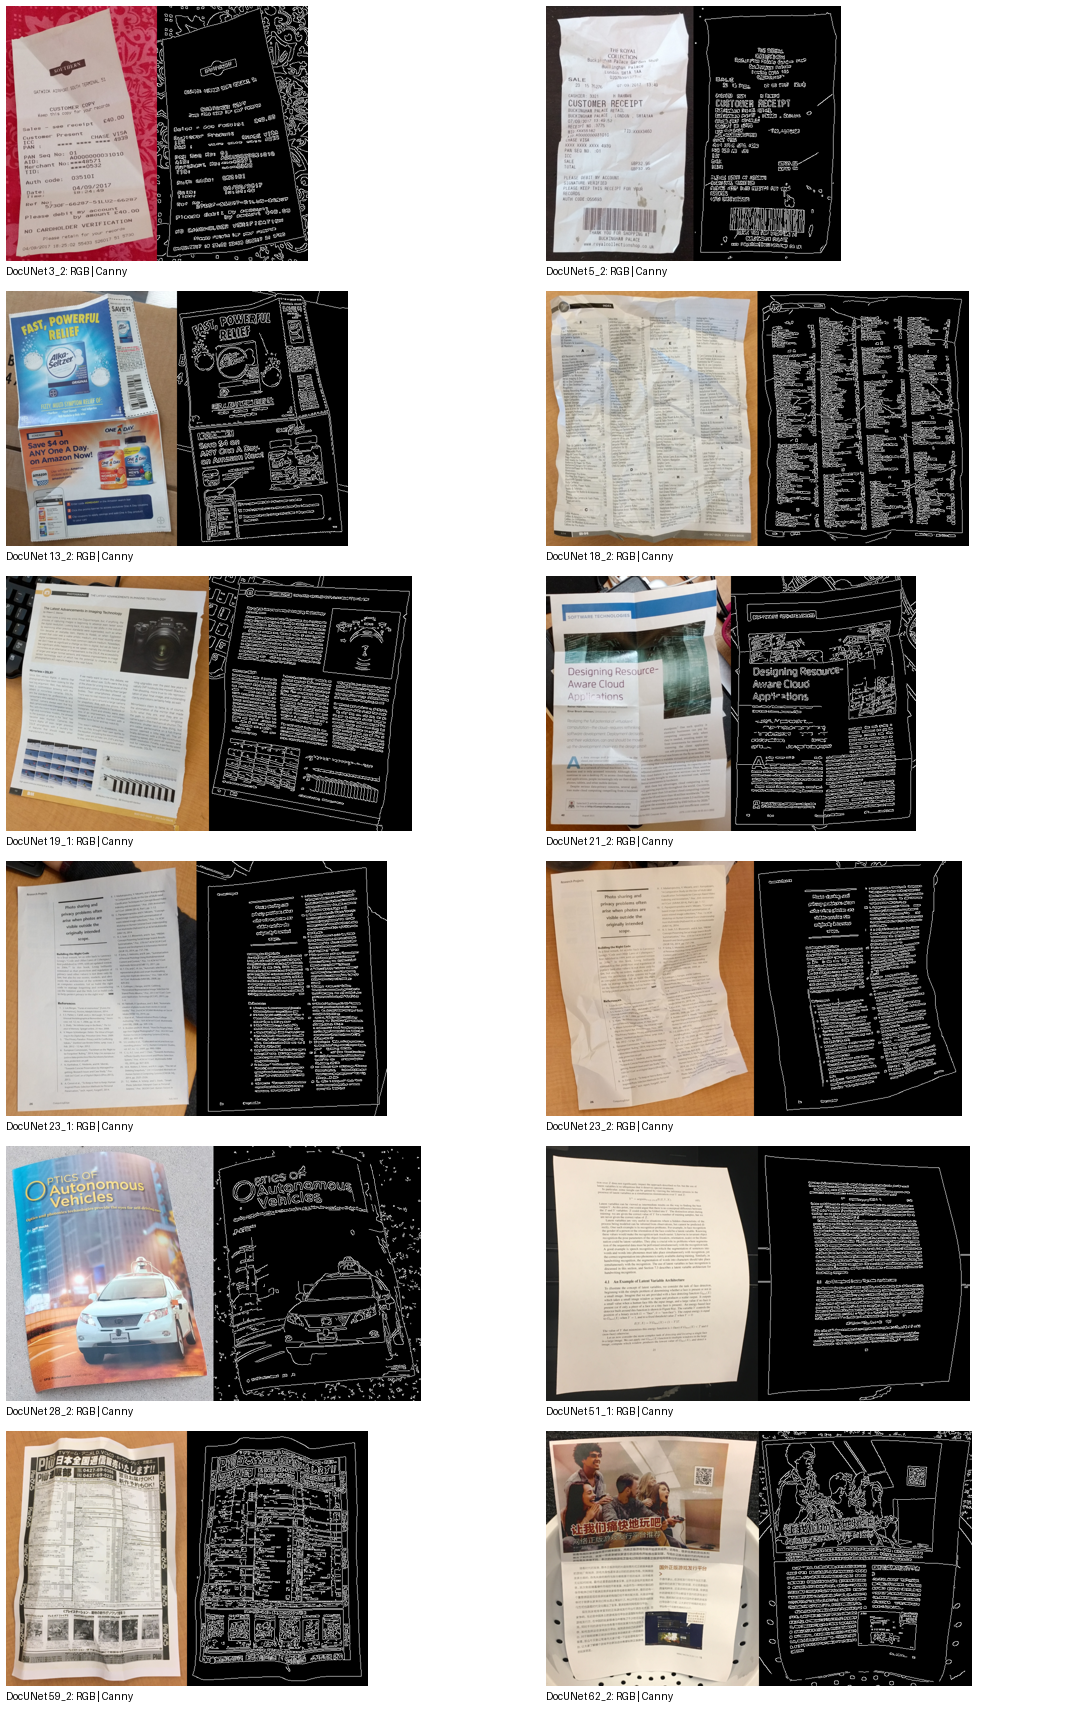

Report updated: /content/drive/MyDrive/Document Unwarping/documentation/dataset_eda_summary.md | 04.04 Classical cue gallery and review template


In [16]:
# 04.04 | Visualize classical probes and create a manual review worksheet
review_examples = pd.concat([sample_ids(classical_table.loc[classical_table.dataset == 'DocUNet'], 12, SEED + 1),
                             sample_ids(classical_table.loc[classical_table.dataset == 'DIR300'], 12, SEED + 2),
                             sample_ids(classical_table.loc[classical_table.dataset == 'UVDoc Final'], 8, SEED + 3)])
review_fields = ['dataset', 'sample_id', 'input_path', 'edge_fraction', 'hough_segments', 'long_segments',
                 'largest_contour_area_fraction']
manual_review = review_examples[review_fields].copy()
for column in ['boundary_visibility', 'corner_visibility', 'curvature_class', 'text_availability',
               'shadow_severity', 'occlusion_or_clipping', 'notes'] :
    manual_review[column] = ''
manual_path = META_ROOT / 'classical_manual_review_template.csv'
if (not manual_path.is_file()) :
    manual_review.to_csv(manual_path, index=False)

probe_gallery = []
for r in review_examples.head(12).itertuples(index=False) :
    rgb  = load_rgb(resolve_path(r.input_path))
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    mask = cv2.Canny(gray, 70, 160)
    pair = np.concatenate([rgb, np.repeat(mask[:, :, None], 3, axis=2)], axis=1)
    probe_gallery.append((f'{r.dataset} {r.sample_id}: RGB | Canny', Image.fromarray(pair)))

canvas_cols, cell_width, cell_height = 2, 540, 285
canvas = Image.new('RGB', (canvas_cols * cell_width, math.ceil(len(probe_gallery) / canvas_cols) * cell_height), 'white')
canvas_draw = ImageDraw.Draw(canvas)
for index, (label, image) in enumerate(probe_gallery) :
    image.thumbnail((cell_width-12, cell_height-30))
    x, y = (index % canvas_cols) * cell_width, (index // canvas_cols) * cell_height
    canvas.paste(image, (x + 6, y + 6))
    canvas_draw.text((x + 6, y + cell_height - 20), label, fill='black')
probe_gallery_path = REVIEW_ROOT / 'classical_probe_gallery.jpg'
canvas.save(probe_gallery_path)
display(canvas.resize((min(canvas.width, 1100), int(canvas.height * min(1100/canvas.width,1)))))
publish('04.04', 'Classical cue gallery and review template',
        'Gallery: `runs/dataset_eda/galleries/classical_probe_gallery.jpg`; '
        'manual worksheet: `dataset/_metadata/classical_manual_review_template.csv`. '
        'The worksheet leaves all qualitative judgments blank for human review. '
        'The companion table identifies each displayed image and its measurable edge/line proxies.',
        {'Gallery IDs and numeric probes' : review_examples.head(12)[review_fields].reset_index(drop=True)})


### 05.01 UVDoc 2D grid conventions and visual verification

The audit found `grid2d` arrays stored in HDF5 with shape `(2, 61, 89)` and `float64`. The official UVDoc loader reads them using `file['grid2d'][:].T.transpose(2, 0, 1)` and interprets raw values as positions in the input image's pixel frame. That produces a tensor of shape `(2, 89, 61)` before the random crop and subsequent normalization. We will verify this through coordinates, corner positions, and overlays. A clean overlay is a necessary visual check; it does not prove every annotation is valid.

In [17]:
# 05.02 | Inspect HDF5 keys, grid conventions, and sample coordinates
def load_grid2d(path : Path) :
    with h5py.File(path, 'r') as file :
        if ('grid2d' not in file) :
            raise KeyError(f'Missing grid2d dataset: {path}')
        return np.array(file['grid2d'][:].T.transpose(2, 0, 1), dtype=np.float64)


def load_grid3d(path : Path) :
    with h5py.File(path, 'r') as file :
        if ('grid3d' not in file) :
            raise KeyError(f'Missing grid3d dataset: {path}')
        return np.array(file['grid3d'][:].T, dtype=np.float64)

probe_grid = pd.concat([sample_ids(uvfinal, 3), sample_ids(uvbench, 3)])
structures = []
for r in probe_grid.itertuples(index=False) :
    p2, p3 = resolve_path(r.grid2d_path), resolve_path(r.grid3d_path)
    with h5py.File(p2) as source :
        raw_shape2 = tuple(source['grid2d'].shape)
    with h5py.File(p3) as source :
        raw_shape3 = tuple(source['grid3d'].shape)
    g2, g3 = load_grid2d(p2), load_grid3d(p3)
    structures.append({'dataset' : r.dataset, 'sample_id' : r.sample_id, 'geom_name' : r.geom_name,
                       'raw_grid2d' : str(raw_shape2), 'loader_grid2d' : str(g2.shape),
                       'raw_grid3d' : str(raw_shape3), 'loader_grid3d' : str(g3.shape),
                       'x_min' : float(np.nanmin(g2[0])), 'x_max' : float(np.nanmax(g2[0])),
                       'y_min' : float(np.nanmin(g2[1])), 'y_max' : float(np.nanmax(g2[1])),
                       'z_min' : float(np.nanmin(g3[:,:,2])), 'z_max' : float(np.nanmax(g3[:,:,2]))})
structure_table = pd.DataFrame(structures)
display(structure_table)
publish('05.02', 'Raw grid inspection',
        'Axes follow the original UVDoc loader; image-space values are **raw pixel coordinates**, not normalized neural-network targets. '
        'The 3D coordinate units are left as released because no physical unit calibration has been verified here.',
        {'Grid structures and ranges' : structure_table})


,dataset,sample_id,geom_name,raw_grid2d,loader_grid2d,raw_grid3d,loader_grid3d,x_min,x_max,y_min,y_max,z_min,z_max
0,UVDoc Final,05470,01_00098_1_1_0,"(2, 61, 89)","(2, 89, 61)","(3, 61, 89)","(89, 61, 3)",51.285178,443.040740,75.672594,598.683226,-0.142537,0.145371
1,UVDoc Final,11816,12_00039_1_0_0,"(2, 61, 89)","(2, 89, 61)","(3, 61, 89)","(89, 61, 3)",86.981478,448.462964,119.039503,649.880692,-0.147423,0.144970
2,UVDoc Final,14074,04_00042_1_1_0,"(2, 61, 89)","(2, 89, 61)","(3, 61, 89)","(89, 61, 3)",69.133322,438.296298,51.954309,587.761430,-0.150072,0.148407
3,UVDoc Benchmark,00011,09_00014_1_0_0,"(2, 61, 89)","(2, 89, 61)","(3, 61, 89)","(89, 61, 3)",15.887554,969.708130,15.499992,1257.935412,-0.155196,0.157616
4,UVDoc Benchmark,00023,09_00028_1_0_0,"(2, 61, 89)","(2, 89, 61)","(3, 61, 89)","(89, 61, 3)",5.499999,937.499992,15.656474,1224.500047,-0.147733,0.143096
5,UVDoc Benchmark,00039,11_00053_1_0_0,"(2, 61, 89)","(2, 89, 61)","(3, 61, 89)","(89, 61, 3)",9.000002,939.999990,12.999986,1188.999949,-0.143029,0.131404


Report updated: /content/drive/MyDrive/Document Unwarping/documentation/dataset_eda_summary.md | 05.02 Raw grid inspection


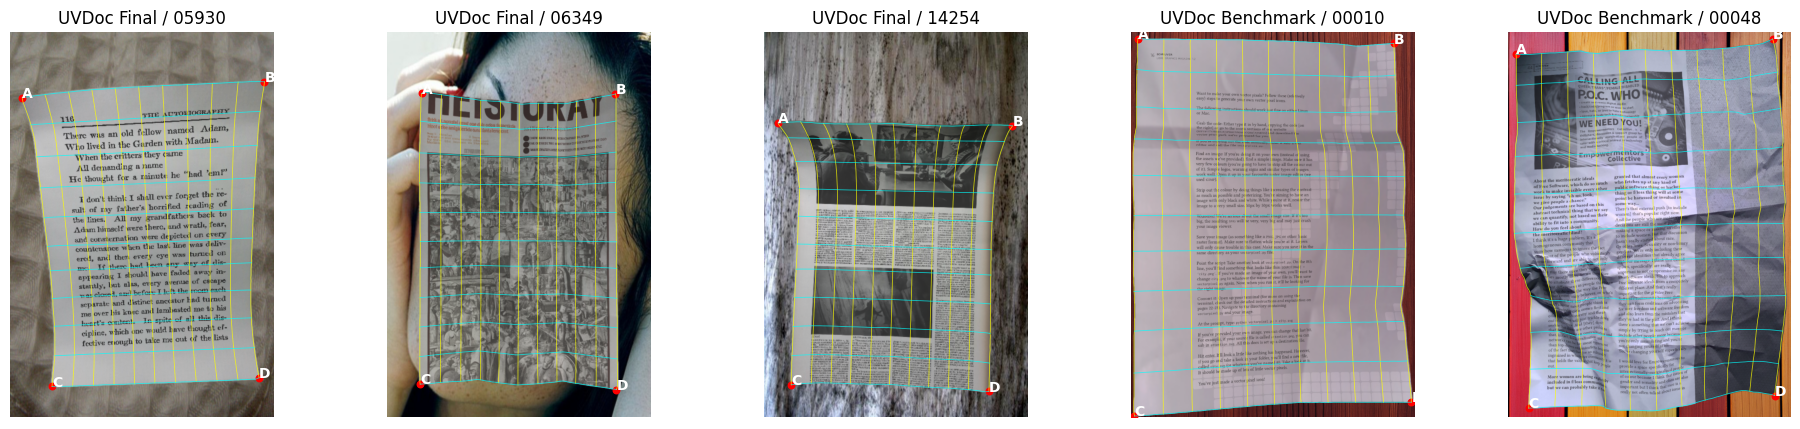

Report updated: /content/drive/MyDrive/Document Unwarping/documentation/dataset_eda_summary.md | 05.03 Image-space grid overlays


In [18]:
# 05.03 | Overlay 2D grids with labeled corners and export corner table
selected_grid_rows = pd.concat([sample_ids(uvfinal, 3, SEED+24), sample_ids(uvbench, 2, SEED+25)])
corner_rows = []
fig, axes = plt.subplots(1, len(selected_grid_rows), figsize=(4.7*len(selected_grid_rows), 5))
for axis, r in zip(axes, selected_grid_rows.itertuples(index=False)) :
    rgb = load_rgb(resolve_path(r.image_path), max_edge=10000)
    grid = load_grid2d(resolve_path(r.grid2d_path))
    axis.imshow(rgb)
    for col in np.linspace(0, grid.shape[2]-1, 11, dtype=int) :
        axis.plot(grid[0,:,col], grid[1,:,col], color='yellow', linewidth=0.6, alpha=0.7)
    for row in np.linspace(0, grid.shape[1]-1, 11, dtype=int) :
        axis.plot(grid[0,row,:], grid[1,row,:], color='cyan', linewidth=0.6, alpha=0.7)
    for label, iy, ix in [('A',0,0),('B',0,-1),('C',-1,0),('D',-1,-1)] :
        x, y = grid[0,iy,ix], grid[1,iy,ix]
        axis.scatter([x], [y], s=22, color='red')
        axis.text(float(x), float(y), label, color='white', fontsize=10, weight='bold')
        corner_rows.append({'dataset' : r.dataset, 'sample_id' : r.sample_id, 'geom_name' : r.geom_name,
                            'corner' : label, 'x_px' : float(x), 'y_px' : float(y),
                            'image_width' : rgb.shape[1], 'image_height' : rgb.shape[0]})
    axis.set_title(f'{r.dataset} / {r.sample_id}')
    axis.axis('off')
corner_table = pd.DataFrame(corner_rows)
figure_with_data('05.03', 'Image-space grid overlays', fig, corner_table,
                 'Corner labels A–D are array-index corners, not presumed document top-left/right labels. '
                 'Use the saved figure to confirm visual correspondence. The companion table gives numerical coordinates and dimensions.')


### 06.01 Full 2D/3D geometry audit

Measure every **unique** geometry variant from both UVDoc releases, not all 20,000 repeated renderings. Full-data checks cover HDF5 shapes, non-finite coordinates, image-frame coverage, grid-cell degeneracy, foldover orientation, 3D depth spread, and best-fitting plane residual. “Foldover” here means a change of grid-cell signed orientation relative to the dominant cell orientation, which requires interpretation before declaring annotation corruption. The plane residual is a scale-normalized geometric descriptor in released coordinate units, not a physical bending measurement in millimeters.

In [19]:
# 06.02 | Compute and cache unique-geometry diagnostics
def geom_stats(r) :
    grid2 = load_grid2d(resolve_path(r.grid2d_path))
    grid3 = load_grid3d(resolve_path(r.grid3d_path))
    if (grid2.shape != (2, 89, 61) or grid3.shape != (89, 61, 3)) :
        raise ValueError(f'Unexpected grid shape: 2D {grid2.shape}, 3D {grid3.shape}')
    uv = grid2.transpose(1,2,0)
    finite2, finite3 = np.isfinite(uv).all(axis=-1), np.isfinite(grid3).all(axis=-1)
    if (not finite2.all() or not finite3.all()) :
        return {'dataset' : r.dataset, 'geom_name' : r.geom_name, 'finite_2d_fraction' : float(finite2.mean()),
                'finite_3d_fraction' : float(finite3.mean()), 'error' : 'Non-finite coordinates'}
    with Image.open(resolve_path(r.image_path)) as img :
        image_width, image_height = img.size
    in_frame = ((uv[:,:,0] >= 0) & (uv[:,:,0] < image_width) &
                (uv[:,:,1] >= 0) & (uv[:,:,1] < image_height))
    h, w = uv.shape[:2]
    horizontal = uv[:,1:,:] - uv[:,:-1,:]
    vertical   = uv[1:,:,:] - uv[:-1,:,:]
    a = horizontal[:-1]
    b = vertical[:,:-1]
    signed_area = a[:,:,0]*b[:,:,1] - a[:,:,1]*b[:,:,0]
    nonzero_area = np.abs(signed_area) > 1e-8
    dominant_sign = np.sign(np.median(signed_area[nonzero_area])) if nonzero_area.any() else 0
    flip_frac = float((np.sign(signed_area[nonzero_area]) != dominant_sign).mean()) if nonzero_area.any() else np.nan
    spacing = np.concatenate([np.linalg.norm(horizontal, axis=-1).ravel(), np.linalg.norm(vertical, axis=-1).ravel()])
    positions = grid3.reshape(-1, 3)
    centered = positions - positions.mean(axis=0)
    eigen = np.linalg.eigvalsh(centered.T @ centered / len(centered))
    diag = np.linalg.norm(np.ptp(positions, axis=0))
    plane_residual = math.sqrt(max(eigen[0], 0)) / diag if diag > 0 else np.nan
    horizontal3 = grid3[:,1:,:] - grid3[:,:-1,:]
    vertical3   = grid3[1:,:,:] - grid3[:-1,:,:]
    normals = np.cross(horizontal3[:-1], vertical3[:,:-1])
    normal_lengths = np.linalg.norm(normals, axis=-1)
    normals = normals / np.maximum(normal_lengths[...,None], 1e-12)
    neighbor_cos = np.concatenate([(normals[1:] * normals[:-1]).sum(axis=-1).ravel(),
                                  (normals[:,1:] * normals[:,:-1]).sum(axis=-1).ravel()])
    normal_angle_p95 = float(np.degrees(np.arccos(np.clip(neighbor_cos, -1, 1))).mean())
    return {'dataset' : r.dataset, 'geom_name' : r.geom_name,
            'finite_2d_fraction' : float(finite2.mean()), 'finite_3d_fraction' : float(finite3.mean()),
            'x_min' : float(uv[:,:,0].min()), 'x_max' : float(uv[:,:,0].max()),
            'y_min' : float(uv[:,:,1].min()), 'y_max' : float(uv[:,:,1].max()),
            'z_min' : float(grid3[:,:,2].min()), 'z_max' : float(grid3[:,:,2].max()),
            'z_span' : float(np.ptp(grid3[:,:,2])),
            'outside_image_fraction' : float(1 - in_frame.mean()),
            'grid_bbox_width_fraction' : float(np.ptp(uv[:,:,0]) / image_width),
            'grid_bbox_height_fraction' : float(np.ptp(uv[:,:,1]) / image_height),
            'grid2d_step_median_px' : float(np.median(spacing)),
            'grid2d_step_p95_px' : float(np.percentile(spacing, 95)),
            'degenerate_cell_fraction' : float(1 - nonzero_area.mean()),
            'orientation_inconsistent_fraction' : flip_frac,
            'plane_residual_normalized' : float(plane_residual),
            'mean_neighbor_normal_angle_deg' : normal_angle_p95,
            'error' : ''}

geometry_cache = META_ROOT / 'uvdoc_geometry_stats.csv'
full_geometry = pd.concat([uvfinal.drop_duplicates('geom_name'), uvbench.drop_duplicates('geom_name')], ignore_index=True)
if (REUSE_CACHED_RESULTS and geometry_cache.is_file()) :
    geometry = pd.read_csv(geometry_cache, keep_default_na=False)
    required_geometry_columns = {'outside_image_fraction','grid_bbox_width_fraction','grid_bbox_height_fraction',
                                 'plane_residual_normalized','mean_neighbor_normal_angle_deg'}
    if (len(geometry) != len(full_geometry) or not required_geometry_columns.issubset(geometry.columns)) :
        geometry = pd.DataFrame()
else :
    geometry = pd.DataFrame()

if (geometry.empty) :
    rows = []
    for r in tqdm(full_geometry.itertuples(index=False), total=len(full_geometry), desc='Read unique 2D/3D geometries') :
        try :
            rows.append(geom_stats(r))
        except (OSError, KeyError, ValueError, FloatingPointError) as exc :
            rows.append({'dataset' : r.dataset, 'geom_name' : r.geom_name, 'error' : f'{type(exc).__name__}: {exc}'})
    geometry = pd.DataFrame(rows)
    geometry.to_csv(geometry_cache, index=False)

geometry_good = geometry.loc[geometry.error == ''].copy()
geom_columns = ['grid_bbox_width_fraction', 'grid_bbox_height_fraction', 'outside_image_fraction',
                'grid2d_step_median_px', 'grid2d_step_p95_px', 'degenerate_cell_fraction',
                'orientation_inconsistent_fraction', 'z_span', 'plane_residual_normalized',
                'mean_neighbor_normal_angle_deg']
geom_summary = geometry_good.groupby('dataset')[geom_columns].agg(['median', 'mean', 'min', 'max']).round(6)
geom_summary.columns = ['_'.join(c) for c in geom_summary.columns]
geom_summary = geom_summary.reset_index()
print('Geometry success:', len(geometry_good), '/', len(full_geometry))
display(geom_summary)
publish('06.02', 'Full unique-geometry audit',
        f'{len(full_geometry):,} unique geometry variants are eligible for analysis. '
        'Plane residual is PCA deviation divided by 3D bbox diagonal. Neighbor normal change is a surface-shape proxy. '
        'Failures and outliers should be inspected on the image overlays rather than classified automatically as bad data.',
        {'Geometry summary' : geom_summary, 'Geometry failures' : geometry.loc[geometry.error != '']})


Read unique 2D/3D geometries:   0%|          | 0/4082 [00:00<?, ?it/s]

Geometry success: 4082 / 4082


,dataset,grid_bbox_width_fraction_median,grid_bbox_width_fraction_mean,grid_bbox_width_fraction_min,grid_bbox_width_fraction_max,grid_bbox_height_fraction_median,grid_bbox_height_fraction_mean,grid_bbox_height_fraction_min,grid_bbox_height_fraction_max,outside_image_fraction_median,...,z_span_min,z_span_max,plane_residual_normalized_median,plane_residual_normalized_mean,plane_residual_normalized_min,plane_residual_normalized_max,mean_neighbor_normal_angle_deg_median,mean_neighbor_normal_angle_deg_mean,mean_neighbor_normal_angle_deg_min,mean_neighbor_normal_angle_deg_max
0,UVDoc Benchmark,0.972689,0.973262,0.955916,0.989424,0.979422,0.978943,0.965739,0.990427,0.0,...,0.269295,0.326527,0.022824,0.022053,0.004373,0.048977,3.753915,3.725876,2.403367,5.126488
1,UVDoc Final,0.788096,0.795342,0.687457,0.967637,0.756345,0.761523,0.647381,0.931836,0.0,...,0.248489,0.345136,0.015561,0.017741,0.001995,0.063680,3.271865,3.392795,2.129409,7.044246


Report updated: /content/drive/MyDrive/Document Unwarping/documentation/dataset_eda_summary.md | 06.02 Full unique-geometry audit


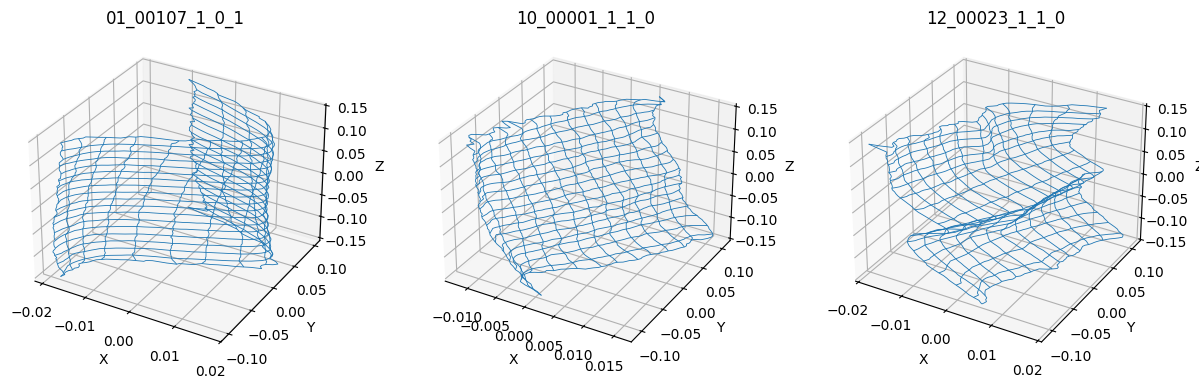

Report updated: /content/drive/MyDrive/Document Unwarping/documentation/dataset_eda_summary.md | 06.03 3D surface examples and extremes


In [20]:
# 06.03 | Inspect extreme 3D shapes and export selected IDs
ranked = []
for key in ['plane_residual_normalized', 'z_span', 'orientation_inconsistent_fraction',
            'degenerate_cell_fraction', 'mean_neighbor_normal_angle_deg'] :
    subset = geometry_good[['dataset','geom_name',key]].dropna().sort_values(key)
    if (not subset.empty) :
        for r in pd.concat([subset.head(3), subset.tail(3)]).itertuples(index=False) :
            ranked.append({'descriptor' : key, 'dataset' : r[0], 'geom_name' : r[1],
                           'value' : float(r[2]), 'extreme' : 'low' if r in list(subset.head(3).itertuples(index=False)) else 'high'})
ranked_geometry = pd.DataFrame(ranked).drop_duplicates()
ranked_geometry.to_csv(META_ROOT / 'uvdoc_geometry_extremes.csv', index=False)
selected_shapes = sample_ids(uvfinal.drop_duplicates('geom_name'), 3, SEED + 49)
fig = plt.figure(figsize=(5 * len(selected_shapes), 4.3))
shape_rows = []
for i, row in enumerate(selected_shapes.itertuples(index=False), start=1) :
    grid = load_grid3d(resolve_path(row.grid3d_path))
    ax = fig.add_subplot(1, len(selected_shapes), i, projection='3d')
    ax.plot_wireframe(grid[:,:,0], grid[:,:,1], grid[:,:,2], rstride=5, cstride=5, linewidth=0.6)
    ax.set_title(row.geom_name)
    ax.set_xlabel('X'); ax.set_ylabel('Y'); ax.set_zlabel('Z')
    shape_rows.append({'geom_name' : row.geom_name, 'sample_id' : row.sample_id,
                       'x_range' : float(np.ptp(grid[:,:,0])), 'y_range' : float(np.ptp(grid[:,:,1])),
                       'z_range' : float(np.ptp(grid[:,:,2]))})
shape_table = pd.DataFrame(shape_rows)
figure_with_data('06.03', '3D surface examples and extremes', fig, shape_table,
                 '3D wireframe visualizes the observed surface in arbitrary released coordinates. '
                 'The table provides per-axis spans and sample IDs; the full extreme ranking is in '
                 '`dataset/_metadata/uvdoc_geometry_extremes.csv`.')


### 07.01 Auxiliary annotations and generation metadata

Inspect a **small** transparent sample of `seg`, `uvmap`, `img_geom`, `warped_textures`, and `metadata_geom`. These files are not automatically aligned with the rendered input at the same resolution, and `wc` is EXR. Record storage shape, value ranges, sample IDs, and whether masks visually align. Do not claim mask accuracy or map orientation without checking it. The `split.json` release structure has `textures`, `backgrounds`, and `geoms`; it should not be mistaken for a sample-level train/validation manifest.

In [21]:
# 07.02 | Audit auxiliary HDF5/JSON examples and split.json
aux_rows = []
for dataset_name, frame in [('UVDoc Final', uvfinal), ('UVDoc Benchmark', uvbench)] :
    root = FINAL_ROOT if dataset_name == 'UVDoc Final' else BENCH_ROOT
    for r in sample_ids(frame.drop_duplicates('geom_name'), MAX_MASK_GEOMETRIES, SEED + len(dataset_name)).itertuples(index=False) :
        for folder, field in [('seg','seg'), ('uvmap','uvmap')] :
            source = root / folder / f'{r.geom_name}.mat'
            try :
                with h5py.File(source) as file :
                    for name in file.keys() :
                        item = file[name]
                        if (isinstance(item, h5py.Dataset)) :
                            value = np.asarray(item)
                            aux_rows.append({'dataset' : dataset_name, 'sample_id' : r.sample_id,
                                             'geom_name' : r.geom_name, 'folder' : folder, 'key' : name,
                                             'shape' : str(value.shape), 'dtype' : str(value.dtype),
                                             'min' : float(np.nanmin(value)), 'max' : float(np.nanmax(value)), 'error' : ''})
            except (OSError, ValueError, KeyError) as exc :
                aux_rows.append({'dataset' : dataset_name, 'sample_id' : r.sample_id, 'geom_name' : r.geom_name,
                                 'folder' : folder, 'error' : f'{type(exc).__name__}: {exc}'})
aux_data = pd.DataFrame(aux_rows)
aux_data.to_csv(META_ROOT / 'uvdoc_auxiliary_audit.csv', index=False)

metadata_rows = []
for dataset_name, root in [('UVDoc Final', FINAL_ROOT), ('UVDoc Benchmark', BENCH_ROOT)] :
    split_file = root / 'split.json'
    if (split_file.is_file()) :
        split = json.loads(split_file.read_text(encoding='utf-8'))
        metadata_rows.extend({'dataset' : dataset_name, 'source' : 'split.json', 'key' : str(k),
                              'type' : type(v).__name__, 'length' : len(v) if hasattr(v,'__len__') else None}
                             for k,v in split.items())
    geom_file = next((root / 'metadata_geom').glob('*.json'), None)
    if (geom_file is not None) :
        geom_meta = json.loads(geom_file.read_text(encoding='utf-8'))
        metadata_rows.extend({'dataset' : dataset_name, 'source' : geom_file.name, 'key' : str(k),
                              'type' : type(v).__name__, 'length' : len(v) if hasattr(v,'__len__') else None}
                             for k,v in geom_meta.items())
metadata_table = pd.DataFrame(metadata_rows)
display(aux_data.head(8)); display(metadata_table)
publish('07.02', 'Auxiliary data formats',
        f'Auxiliary array inspection sampled up to {MAX_MASK_GEOMETRIES} unique geometries per release. '
        'Min/max values and array keys describe formats, not proven semantics.',
        {'Auxiliary array inventory' : aux_data.groupby(['dataset','folder','key','shape','dtype'], dropna=False).size().reset_index(name='samples'),
         'Release metadata keys' : metadata_table, 'Auxiliary errors' : aux_data.loc[aux_data.error != '']})


,dataset,sample_id,geom_name,folder,key,shape,dtype,min,max,error
0,UVDoc Final,00155,00_00043_1_1_1,seg,seg,"(488, 712)",uint8,0.0,1.0,
1,UVDoc Final,00155,00_00043_1_1_1,uvmap,uv,"(2, 488, 712)",float64,0.0,1.0,
2,UVDoc Final,00284,00_00077_1_0_0,seg,seg,"(488, 712)",uint8,0.0,1.0,
3,UVDoc Final,00284,00_00077_1_0_0,uvmap,uv,"(2, 488, 712)",float64,0.0,1.0,
4,UVDoc Final,00390,00_00104_1_1_0,seg,seg,"(488, 712)",uint8,0.0,1.0,
5,UVDoc Final,00390,00_00104_1_1_0,uvmap,uv,"(2, 488, 712)",float64,0.0,1.0,
6,UVDoc Final,00450,00_00122_1_1_0,seg,seg,"(488, 712)",uint8,0.0,1.0,
7,UVDoc Final,00450,00_00122_1_1_0,uvmap,uv,"(2, 488, 712)",float64,0.0,1.0,


,dataset,source,key,type,length
0,UVDoc Final,split.json,textures,list,3009
1,UVDoc Final,split.json,backgrounds,list,5640
2,UVDoc Final,split.json,geoms,list,1008
3,UVDoc Final,10_00010_1_1_1.json,sample_id,str,10
4,UVDoc Final,10_00010_1_1_1.json,flip_horizontal,str,4
5,UVDoc Final,10_00010_1_1_1.json,flip_vertical,str,4
6,UVDoc Final,10_00010_1_1_1.json,sample_info,dict,4
7,UVDoc Final,10_00010_1_1_1.json,cam,dict,2
8,UVDoc Benchmark,split.json,textures,list,50
9,UVDoc Benchmark,split.json,backgrounds,list,50


Report updated: /content/drive/MyDrive/Document Unwarping/documentation/dataset_eda_summary.md | 07.02 Auxiliary data formats


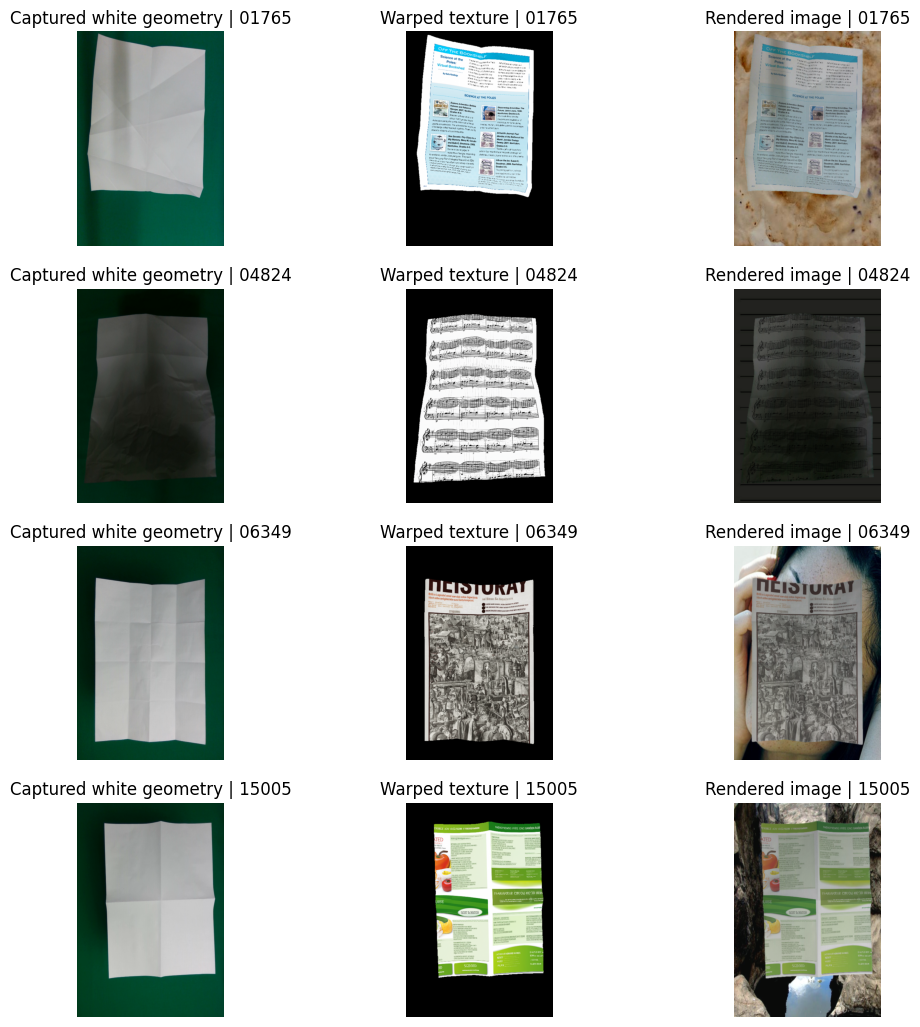

Report updated: /content/drive/MyDrive/Document Unwarping/documentation/dataset_eda_summary.md | 07.03 UVDoc intermediate-image visual audit


In [22]:
# 07.03 | Show UVDoc texture/render and geometry intermediates with identifiers
aux_visual_rows = sample_ids(uvfinal, 4, SEED + 53)
fig, axes = plt.subplots(len(aux_visual_rows), 3, figsize=(12, 3.2*len(aux_visual_rows)))
aux_pairs = []
for i, r in enumerate(aux_visual_rows.itertuples(index=False)) :
    files = [('Captured white geometry', FINAL_ROOT / 'img_geom' / f'{r.geom_name}.png'),
             ('Warped texture', FINAL_ROOT / 'warped_textures' / f'{r.sample_id}.png'),
             ('Rendered image', resolve_path(r.image_path))]
    for ax, (label, path) in zip(axes[i], files) :
        with Image.open(path) as im :
            im.thumbnail((600,600))
            ax.imshow(im)
        ax.axis('off'); ax.set_title(f'{label} | {r.sample_id}')
        aux_pairs.append({'sample_id' : r.sample_id, 'geom_name' : r.geom_name,
                          'role' : label, 'path' : str(path.relative_to(FINAL_ROOT)) if path.is_relative_to(FINAL_ROOT) else str(path)})
figure_with_data('07.03', 'UVDoc intermediate-image visual audit', fig, pd.DataFrame(aux_pairs),
                 'The three image roles follow the filenames in the official dataset release. '
                 'The table records the source of every image shown; no interpretation of color transfer is assumed.')


### 08.01 Synthetic–real comparison

Compare image properties only where the representations are comparable: UVDoc rendered inputs, DocUNet **crops**, and DIR300 **distorted inputs**. UVDoc Benchmark remains a held-out annotated test set. Image statistics suggest possible domain differences, not performance outcomes. For geometry, compare UVDoc Final versus Benchmark only because the real benchmarks do not supply ground-truth 2D/3D grids.

,dataset,descriptor,count,p05,median,p95
0,DIR300,luminance_mean,300,102.557277,132.734922,160.680029
1,DIR300,luminance_std,300,34.681753,56.218541,77.984898
2,DIR300,saturation_mean,300,17.559439,55.238286,100.375390
3,DIR300,edge_fraction,300,0.051887,0.099075,0.186459
4,DIR300,tile_luminance_range,300,48.224805,96.216863,144.180209
5,DIR300,laplacian_variance,300,277.858621,580.004364,1193.635670
6,DocUNet,luminance_mean,130,123.232522,164.963592,193.253947
7,DocUNet,luminance_std,130,31.084990,54.267613,75.970066
8,DocUNet,saturation_mean,130,26.940880,50.421141,83.259123
9,DocUNet,edge_fraction,130,0.065570,0.129131,0.209373


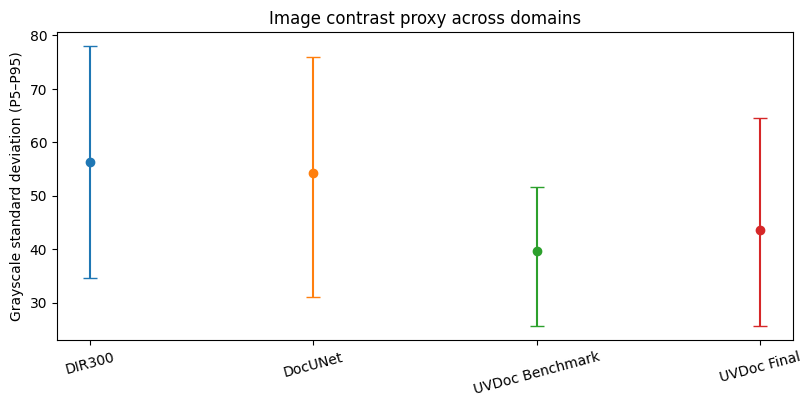

Report updated: /content/drive/MyDrive/Document Unwarping/documentation/dataset_eda_summary.md | 08.02 Photometric domain comparison


In [23]:
# 08.02 | Compare measured photometric descriptors across domains
comparison_columns = ['luminance_mean', 'luminance_std', 'saturation_mean', 'edge_fraction',
                      'tile_luminance_range', 'laplacian_variance']
domain_rows = []
for name, frame in pixel_ok.groupby('dataset') :
    for column in comparison_columns :
        values = frame[column].dropna()
        domain_rows.append({'dataset' : name, 'descriptor' : column, 'count' : len(values),
                            'p05' : float(values.quantile(0.05)), 'median' : float(values.median()),
                            'p95' : float(values.quantile(0.95))})
domain_stats = pd.DataFrame(domain_rows)
display(domain_stats)
fig, ax = plt.subplots(figsize=(9.5, 4))
for name, frame in domain_stats.loc[domain_stats.descriptor == 'luminance_std'].groupby('dataset') :
    ax.errorbar([name], [frame['median'].iloc[0]],
                yerr=[[frame['median'].iloc[0] - frame.p05.iloc[0]], [frame.p95.iloc[0] - frame['median'].iloc[0]]],
                fmt='o', capsize=5)
ax.set(title='Image contrast proxy across domains', ylabel='Grayscale standard deviation (P5–P95)')
ax.tick_params(axis='x', rotation=15)
figure_with_data('08.02', 'Photometric domain comparison', fig, domain_stats,
                 'Figure highlights P5/median/P95 contrast proxy; companion table includes the other descriptors. '
                 'Different sample sizes are visible in `count`, and no statistical significance or causal effect is asserted.')


In [24]:
# 08.03 | Compare training and held-out geometric variation
geom_domain = []
for name, group in geometry_good.groupby('dataset') :
    for column in ['plane_residual_normalized','z_span','mean_neighbor_normal_angle_deg',
                   'orientation_inconsistent_fraction'] :
        values = group[column].dropna()
        geom_domain.append({'dataset' : name, 'descriptor' : column, 'n' : len(values),
                            'p05' : float(values.quantile(0.05)), 'median' : float(values.median()),
                            'p95' : float(values.quantile(0.95))})
geom_domain_table = pd.DataFrame(geom_domain)
display(geom_domain_table)
publish('08.03', 'Annotated geometry comparison',
        'Geometric descriptors are from supplied UVDoc annotations only. Their distributions measure differences between '
        'training and benchmark geometry, not outcomes of an unwarping model.',
        {'Geometry distributions by release' : geom_domain_table})


,dataset,descriptor,n,p05,median,p95
0,UVDoc Benchmark,plane_residual_normalized,50,0.006185,0.022824,0.045380
1,UVDoc Benchmark,z_span,50,0.274534,0.292922,0.313148
2,UVDoc Benchmark,mean_neighbor_normal_angle_deg,50,2.641328,3.753915,4.996586
3,UVDoc Benchmark,orientation_inconsistent_fraction,50,0.000000,0.000000,0.000000
4,UVDoc Final,plane_residual_normalized,4032,0.004495,0.015561,0.037931
5,UVDoc Final,z_span,4032,0.280040,0.294497,0.303503
6,UVDoc Final,mean_neighbor_normal_angle_deg,4032,2.397186,3.271865,4.861947
7,UVDoc Final,orientation_inconsistent_fraction,4032,0.000000,0.000000,0.000000


Report updated: /content/drive/MyDrive/Document Unwarping/documentation/dataset_eda_summary.md | 08.03 Annotated geometry comparison


### 09.01 Real-world reference compatibility

DocUNet's 65 flat scans are shared by two photographs each. DIR300 contains one distorted/reference pair per ID. These references are not dense deformation maps or verified OCR transcripts. Inspect orientation, modes, transparency, aspect ratios, and whether either image contains missing page content. Report, but **never automatically fix**, the known DocUNet 64_1 and 64_2 orientation questions.

In [25]:
# 09.02 | Pair distorted inputs with references and report mismatches
meta_lookup = valid_meta.set_index(['dataset', 'path'])
benchmark_pairs = []
for name in ('DocUNet','DIR300') :
    for r in manifests[name].itertuples(index=False) :
        try :
            inp = meta_lookup.loc[(name,r.input_path)]
            ref = meta_lookup.loc[(name,r.reference_path)]
            input_aspect = float(inp.aspect_ratio)
            reference_aspect = float(ref.aspect_ratio)
            benchmark_pairs.append({'dataset' : name, 'sample_id' : r.sample_id,
                'document_id' : r.document_id, 'input_path' : r.input_path, 'reference_path' : r.reference_path,
                'input_width' : int(inp.width), 'input_height' : int(inp.height),
                'reference_width' : int(ref.width), 'reference_height' : int(ref.height),
                'input_mode' : inp['mode'], 'reference_mode' : ref['mode'],
                'input_orientation' : int(inp.exif_orientation), 'reference_orientation' : int(ref.exif_orientation),
                'aspect_log_ratio' : float(np.log(input_aspect / reference_aspect)),
                'orientation_category_mismatch' : bool((inp.width > inp.height) != (ref.width > ref.height)),
                'needs_visual_review' : bool(name == 'DocUNet' and str(r.sample_id) in {'64_1','64_2'})})
        except KeyError as exc :
            benchmark_pairs.append({'dataset' : name, 'sample_id' : r.sample_id, 'error' : str(exc)})
pair_table = pd.DataFrame(benchmark_pairs)
pair_table.to_csv(META_ROOT / 'benchmark_pair_audit.csv', index=False)
pair_summary = pair_table.groupby('dataset').agg(n=('sample_id', 'size'),
    orientation_category_mismatches=('orientation_category_mismatch','sum'),
    flagged_for_visual_review=('needs_visual_review','sum'),
    median_abs_log_aspect_ratio=('aspect_log_ratio',lambda x : x.abs().median())).reset_index()
display(pair_summary)
publish('09.02', 'Real benchmark reference compatibility',
        'Aspect/log-ratio and portrait/landscape differences are descriptive warnings; '
        'they are not automatic errors or reasons to exclude examples. '
        'DocUNet 64_1 and 64_2 are explicitly flagged for manual inspection.',
        {'Benchmark pair summary' : pair_summary,
         'Potential orientation/category cases' : pair_table.loc[pair_table.orientation_category_mismatch | pair_table.needs_visual_review,
             ['dataset','sample_id','input_path','reference_path','aspect_log_ratio','needs_visual_review']]})


,dataset,n,orientation_category_mismatches,flagged_for_visual_review,median_abs_log_aspect_ratio
0,DIR300,300,0,0,0.069946
1,DocUNet,130,2,2,0.074836


Report updated: /content/drive/MyDrive/Document Unwarping/documentation/dataset_eda_summary.md | 09.02 Real benchmark reference compatibility


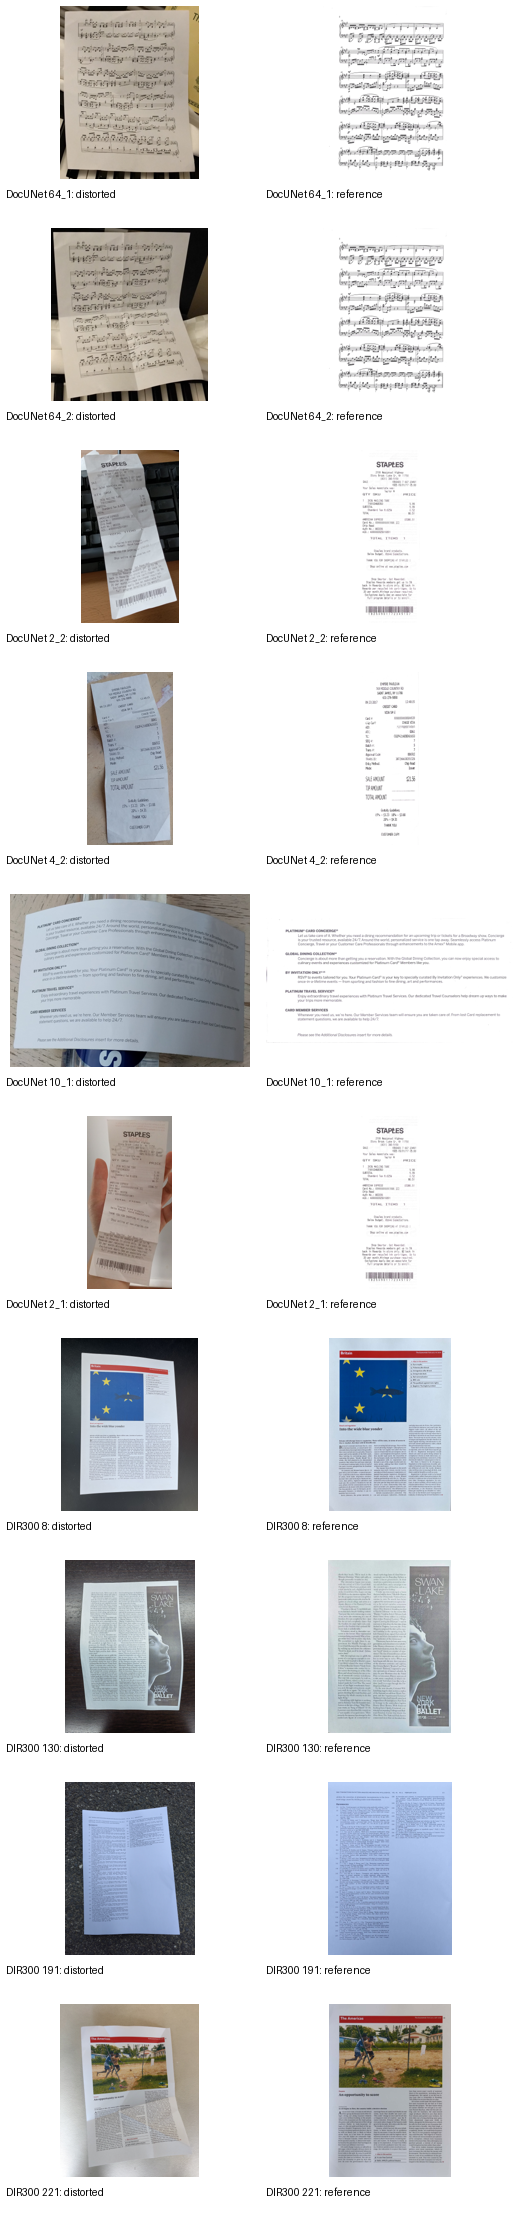

Report updated: /content/drive/MyDrive/Document Unwarping/documentation/dataset_eda_summary.md | 09.03 Real benchmark paired gallery


In [26]:
# 09.03 | Show difficult pairing examples with a text identity table
examples = pair_table.loc[pair_table.dataset == 'DocUNet']
important = examples.loc[examples.sample_id.isin(['64_1','64_2'])]
remaining = examples.loc[~examples.sample_id.isin(['64_1','64_2'])]
selected_pairs = pd.concat([important, remaining.reindex(remaining.aspect_log_ratio.abs().sort_values(ascending=False).index).head(4),
                            sample_ids(pair_table.loc[pair_table.dataset == 'DIR300'], 4, SEED+9)], ignore_index=True)
items = []
for r in selected_pairs.itertuples(index=False) :
    items.extend([(f'{r.dataset} {r.sample_id}: distorted', resolve_path(r.input_path)),
                  (f'{r.dataset} {r.sample_id}: reference', resolve_path(r.reference_path))])
pair_gallery_path = REVIEW_ROOT / 'benchmark_reference_pairs.jpg'
make_contact_sheet(items, 'Paired real benchmark examples', pair_gallery_path, columns=2)
publish('09.03', 'Real benchmark paired gallery',
        'Gallery: `runs/dataset_eda/galleries/benchmark_reference_pairs.jpg`. '
        'The companion table records all displayed pairs and dimensions. '
        'Inspect orientation and content manually before setting an evaluation alignment rule.',
        {'Displayed pairs' : selected_pairs[['dataset','sample_id','input_path','reference_path','input_width',
                                             'input_height','reference_width','reference_height','aspect_log_ratio']]})


### 10.01 Group-disjoint training and validation split

A split by random images or by the full five-part `geom_name` can leak sibling variants across sets. For UVDoc Final, this notebook verifies the four-variant pattern and proposes a fixed, seeded split on the **base capture identifier** (remove final two numeric suffixes). It exports immutable candidate train/validation lists and a split specification; the real test sets are never used for selecting or balancing the split. We compare image/geometry distributions *after* splitting without resampling based on observed benchmark outcomes.

In [27]:
# 10.02 | Build a capture-grouped split and verify no overlap
if (not uvfinal.geom_name.str.fullmatch(r'[^_]+_[^_]+_[^_]+_[01]_[01]').all()) :
    raise ValueError('Geometry identifier format differs from the expected four-variant pattern. Review grouping before splitting.')
variant_sets = uvfinal.groupby('base_geometry').variant.agg(lambda s : set(s)).to_dict()
expected_variants = {'0_0','0_1','1_0','1_1'}
invalid_groups = [g for g, variants in variant_sets.items() if variants != expected_variants]
if (invalid_groups) :
    raise ValueError(f'Base geometry groups have unexpected variant membership: {invalid_groups[:10]}')

rng    = np.random.default_rng(SEED)
groups = np.array(sorted(uvfinal.base_geometry.unique()))
shuffled = rng.permutation(groups)
n_val    = max(1, round(len(groups) * VALIDATION_FRACTION))
val_group_ids   = set(shuffled[:n_val])
train_group_ids = set(shuffled[n_val:])
assert not (train_group_ids & val_group_ids)
assert train_group_ids | val_group_ids == set(groups)

uv_split = uvfinal.copy()
uv_split['split'] = np.where(uv_split.base_geometry.isin(val_group_ids), 'val', 'train')
train_samples = uv_split.loc[uv_split.split == 'train'].sort_values('sample_id')
val_samples   = uv_split.loc[uv_split.split == 'val'].sort_values('sample_id')
assert set(train_samples.geom_name).isdisjoint(set(val_samples.geom_name))
assert set(train_samples.base_geometry).isdisjoint(set(val_samples.base_geometry))
assert len(train_samples) + len(val_samples) == len(uvfinal)

split_summary = uv_split.groupby('split').agg(images=('sample_id','size'),
    geometry_variants=('geom_name','nunique'), base_captures=('base_geometry','nunique'),
    textures=('texture_name','nunique'), backgrounds=('background_name','nunique')).reset_index()
shared_textures = set(train_samples.texture_name) & set(val_samples.texture_name)
shared_backgrounds = set(train_samples.background_name) & set(val_samples.background_name)
split_overlap = pd.DataFrame([{'identity' : 'base_geometry', 'shared' : 0},
                              {'identity' : 'geom_name', 'shared' : 0},
                              {'identity' : 'texture_name', 'shared' : len(shared_textures)},
                              {'identity' : 'background_name', 'shared' : len(shared_backgrounds)}])
display(split_summary); display(split_overlap)
publish('10.02', 'Proposed grouped split',
        f'Validation groups: {n_val:,} of {len(groups):,}, seed={SEED}. '
        'The last two geometry ID bits enumerate four variants per base; all variants are kept together. '
        'Repeated textures/backgrounds are quantified rather than incorrectly claimed absent.',
        {'Split sizes' : split_summary, 'Split source overlap' : split_overlap})


,split,images,geometry_variants,base_captures,textures,backgrounds
0,train,17992,3628,907,3001,5410
1,val,2008,404,101,1475,1681


,identity,shared
0,base_geometry,0
1,geom_name,0
2,texture_name,1473
3,background_name,1621


Report updated: /content/drive/MyDrive/Document Unwarping/documentation/dataset_eda_summary.md | 10.02 Proposed grouped split


In [28]:
# 10.03 | Compare grouped train/validation distributions
split_geom = geometry_good.loc[geometry_good.dataset == 'UVDoc Final'].merge(
    uv_split[['geom_name','split','base_geometry']].drop_duplicates('geom_name'), on='geom_name', how='inner', validate='one_to_one')
compare_rows = []
for key in ['plane_residual_normalized','z_span','mean_neighbor_normal_angle_deg',
            'orientation_inconsistent_fraction'] :
    for split, group in split_geom.groupby('split') :
        values = group[key].dropna()
        compare_rows.append({'descriptor' : key, 'split' : split, 'n_unique_geometries' : len(values),
                             'median' : float(values.median()), 'p05' : float(values.quantile(.05)),
                             'p95' : float(values.quantile(.95))})
geom_split_comparison = pd.DataFrame(compare_rows)
print('Description-only comparison; no split was optimized against downstream test scores.')
display(geom_split_comparison)
publish('10.03', 'Train/validation geometry balance',
        'The reported distributions describe the fixed capture-grouped split. '
        'If severe imbalance appears, document it rather than repeatedly searching for a seed that improves test scores.',
        {'Geometry descriptors by split' : geom_split_comparison})


Description-only comparison; no split was optimized against downstream test scores.


,descriptor,split,n_unique_geometries,median,p05,p95
0,plane_residual_normalized,train,3628,0.015773,0.004910,0.037931
1,plane_residual_normalized,val,404,0.013799,0.004327,0.036660
2,z_span,train,3628,0.294492,0.280270,0.303234
3,z_span,val,404,0.294739,0.279667,0.305853
4,mean_neighbor_normal_angle_deg,train,3628,3.276366,2.401601,4.862016
5,mean_neighbor_normal_angle_deg,val,404,3.238054,2.394480,4.600917
6,orientation_inconsistent_fraction,train,3628,0.000000,0.000000,0.000000
7,orientation_inconsistent_fraction,val,404,0.000000,0.000000,0.000000


Report updated: /content/drive/MyDrive/Document Unwarping/documentation/dataset_eda_summary.md | 10.03 Train/validation geometry balance


In [29]:
# 10.04 | Export the fixed split specification without silent replacement
train_path = META_ROOT / 'uvdoc_train.csv'
val_path   = META_ROOT / 'uvdoc_val.csv'
spec_path  = META_ROOT / 'split_spec.json'
split_spec = {'dataset' : 'UVDoc Final', 'policy' : 'base_geometry_group_disjoint',
              'base_geometry_rule' : 'geom_name.rsplit("_", 2)[0]; only if four variants 0_0,0_1,1_0,1_1 verified',
              'seed' : SEED, 'validation_fraction_of_groups' : VALIDATION_FRACTION,
              'training_groups' : len(train_group_ids), 'validation_groups' : len(val_group_ids),
              'training_samples' : len(train_samples), 'validation_samples' : len(val_samples),
              'held_out' : ['UVDoc Benchmark','DocUNet','DIR300']}
if (spec_path.is_file()) :
    old_spec = json.loads(spec_path.read_text(encoding='utf-8'))
    critical = ['policy','seed','validation_fraction_of_groups','training_samples','validation_samples']
    if (any(old_spec.get(k) != split_spec[k] for k in critical)) :
        raise RuntimeError('A different split_spec.json already exists. Review it before replacing train/validation files.')

if (train_path.is_file() and val_path.is_file()) :
    existing_train = set(pd.read_csv(train_path, dtype={'sample_id':str}).sample_id)
    existing_val = set(pd.read_csv(val_path, dtype={'sample_id':str}).sample_id)
    if (existing_train != set(train_samples.sample_id) or existing_val != set(val_samples.sample_id)) :
        raise RuntimeError('Existing split files differ from this seeded split. Resolve deliberately, not by overwriting.')
else :
    train_samples.to_csv(train_path, index=False)
    val_samples.to_csv(val_path, index=False)
    spec_path.write_text(json.dumps(split_spec, indent=2), encoding='utf-8')

split_export = pd.DataFrame([{'file' : 'dataset/_metadata/uvdoc_train.csv', 'rows' : len(train_samples)},
                             {'file' : 'dataset/_metadata/uvdoc_val.csv', 'rows' : len(val_samples)},
                             {'file' : 'dataset/_metadata/split_spec.json', 'rows' : 1}])
display(split_export)
publish('10.04', 'Exported train and validation definitions',
        'No original images/grids were moved or modified. This is a proposed reproducible local validation split; '
        'it is not the training/validation protocol used in the original UVDoc paper.',
        {'Split output files' : split_export})


,file,rows
0,dataset/_metadata/uvdoc_train.csv,17992
1,dataset/_metadata/uvdoc_val.csv,2008
2,dataset/_metadata/split_spec.json,1


Report updated: /content/drive/MyDrive/Document Unwarping/documentation/dataset_eda_summary.md | 10.04 Exported train and validation definitions


### 11.01 Consolidated findings and uploadable report

The full report at `documentation/dataset_eda_summary.md` is **the main uploadable deliverable**. It includes each stage's measured figures, numeric companion tables, relevant examples, and links to full CSV files. Figures are saved separately under `runs/dataset_eda/figures/` and `runs/dataset_eda/galleries/`. The report lists outstanding interpretive tasks, especially manual page-boundary/text-line labels and visual grid-overlay verification. Do not mistake this notebook's diagnostics for a trained baseline, a classical algorithm, or a published-score benchmark evaluation.

In [30]:
# 11.02 | Write final methodological findings and completion checklist
problems = []
for name in manifests :
    if (not integrity[source_keys[name]].get('ready', False)) :
        problems.append(f'{name}: integrity report not ready')
if (len(geometry_good) != len(full_geometry)) :
    problems.append(f'Only {len(geometry_good)}/{len(full_geometry)} unique geometries passed numerical audit')
if (not failed_images.empty) :
    problems.append(f'{len(failed_images)} image headers could not be read')
if (not pixels.loc[pixels.error != ''].empty) :
    problems.append(f'{len(pixels.loc[pixels.error != ""])} sampled images failed pixel decoding')
if (not classical_table.loc[classical_table.error != ''].empty) :
    problems.append('Some classical cue probes failed')

outcome = pd.DataFrame([
    {'research_area' : 'Deep-learning supervision', 'finding_or_next_check' : 'Raw 2D/3D grid load and normalization conventions are distinguished; visually verify grid overlays.'},
    {'research_area' : 'Validation design', 'finding_or_next_check' : 'Use disjoint base captures, not independent rendered images or only full geometry variants.'},
    {'research_area' : 'Held-out evaluation', 'finding_or_next_check' : 'UVDoc Benchmark, DocUNet and DIR300 are excluded from the train/validation split.'},
    {'research_area' : 'Classical boundaries', 'finding_or_next_check' : 'Inspect Canny/contour galleries and fill the manual-review worksheet; automatic contours are not labels.'},
    {'research_area' : 'Classical text lines', 'finding_or_next_check' : 'Use line-candidate statistics as probes; manually verify whether lines correspond to printed text.'},
    {'research_area' : 'Reference compatibility', 'finding_or_next_check' : 'Inspect flagged orientation/content pairs, including DocUNet 64_1 and 64_2, before formal metric evaluation.'},
    {'research_area' : 'Synthetic to real', 'finding_or_next_check' : 'Use recorded domain differences as hypotheses, not proven causes of model errors.'},
    {'research_area' : 'Dataset completeness', 'finding_or_next_check' : 'Re-run actual path and annotation checks whenever temporary Colab storage resets.'},
])
issue_table = pd.DataFrame({'outstanding_issue' : problems}) if problems else pd.DataFrame([{'outstanding_issue' : 'No automatic audit failures observed; human visual checks still required.'}])
publish('11.02', 'Research-readiness conclusions and limitations',
        'EDA is now summarized independently of notebook plot outputs. '
        'Figures and numerical companions, sampling limits, split policy, and outstanding issues are recorded above. '
        'Visual manual-review labels remain unfilled until somebody actually inspects those examples.',
        {'Method implications' : outcome, 'Unresolved issues' : issue_table})
print(f'REPORT READY: {REPORT_PATH}')
print(f'Figures: {FIG_ROOT}')
print(f'Galleries: {REVIEW_ROOT}')
print('Attach the Markdown report to the next conversation. Add CSVs only when detailed row-level analysis is needed.')


Report updated: /content/drive/MyDrive/Document Unwarping/documentation/dataset_eda_summary.md | 11.02 Research-readiness conclusions and limitations
REPORT READY: /content/drive/MyDrive/Document Unwarping/documentation/dataset_eda_summary.md
Figures: /content/drive/MyDrive/Document Unwarping/runs/dataset_eda/figures
Galleries: /content/drive/MyDrive/Document Unwarping/runs/dataset_eda/galleries
Attach the Markdown report to the next conversation. Add CSVs only when detailed row-level analysis is needed.
